# FitScore AI – Resume Screening and Candidate Ranking System

## Phase 1: Dataset Analysis and Preparation
Loads `resume_screening_dataset.csv` (10,000 rows, 10 columns), verifies data quality, explores feature and text distributions, inspects synthetic rule-based labels, and cleans text in memory (`df_clean`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the original dataset directly (do not modify the CSV file)
df = pd.read_csv("resume_screening_dataset.csv")

print("Dataset Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
print("\nDataset Info:")
df.info()

df.head(3)

Dataset Shape (rows, columns): (10000, 10)
Columns: ['Candidate_ID', 'Role', 'Resume', 'Job_Description', 'Years_Experience', 'Education_Level', 'Num_Projects', 'Num_Certifications', 'Decision', 'Reason_for_decision']

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Candidate_ID         10000 non-null  str  
 1   Role                 10000 non-null  str  
 2   Resume               10000 non-null  str  
 3   Job_Description      10000 non-null  str  
 4   Years_Experience     10000 non-null  int64
 5   Education_Level      10000 non-null  str  
 6   Num_Projects         10000 non-null  int64
 7   Num_Certifications   10000 non-null  int64
 8   Decision             10000 non-null  str  
 9   Reason_for_decision  10000 non-null  str  
dtypes: int64(3), str(7)
memory usage: 13.3 MB


,Candidate_ID,Role,Resume,Job_Description,Years_Experience,Education_Level,Num_Projects,Num_Certifications,Decision,Reason_for_decision
0,C06253,Cloud Engineer,Kavya Smith\r\nCloud Engineer\r\nEmail: kavya....,Join us as a Cloud Engineer. Key skills: Amazo...,7,Master's,3,3,select,Matches 6 of 7 required skills; meets the expe...
1,C04685,Full Stack Developer,Ava Nair\r\nFull Stack Developer\r\nEmail: ava...,Full Stack Developer opening: we are looking f...,9,Master's,4,1,reject,"Missing required skills: git, rest apis, css."
2,C01732,DevOps Engineer,Daniel Johnson\r\nCybersecurity Analyst\r\nEma...,Our growing company needs a DevOps Engineer sk...,1,Master's,4,0,reject,"Missing required skills: aws, monitoring, kube..."


In [2]:
print("Missing Values per Column:")
print(df.isnull().sum())

print("\nExact Duplicate Rows:", df.duplicated().sum())
print("Duplicate Candidate_IDs:", df["Candidate_ID"].duplicated().sum())
print("Duplicate Resumes:", df["Resume"].duplicated().sum())
print("Duplicate (Resume, Job_Description) pairs:", df.duplicated(subset=["Resume", "Job_Description"]).sum())

print("\nUnique Values per Column:")
print(df.nunique())

jd_group_sizes = df["Job_Description"].value_counts()
print("\nCandidates per Job Description (min / max):", jd_group_sizes.min(), "/", jd_group_sizes.max())

Missing Values per Column:
Candidate_ID           0
Role                   0
Resume                 0
Job_Description        0
Years_Experience       0
Education_Level        0
Num_Projects           0
Num_Certifications     0
Decision               0
Reason_for_decision    0
dtype: int64

Exact Duplicate Rows: 0
Duplicate Candidate_IDs: 0
Duplicate Resumes: 0
Duplicate (Resume, Job_Description) pairs: 0

Unique Values per Column:
Candidate_ID           10000
Role                      15
Resume                 10000
Job_Description         1500
Years_Experience          16
Education_Level            4
Num_Projects               7
Num_Certifications         4
Decision                   2
Reason_for_decision     4716
dtype: int64

Candidates per Job Description (min / max): 6 / 7


In [3]:
print("Numeric Summary:")
display(df.describe().round(2))

print("\nDecision Counts and Percentages:")
print(df["Decision"].value_counts())
print((df["Decision"].value_counts(normalize=True) * 100).round(2))

print("\nRole Counts (15 Roles):")
print(df["Role"].value_counts())

print("\nEducation Level Counts:")
print(df["Education_Level"].value_counts())

# Measure text lengths in characters and words
resume_words = df["Resume"].str.split().str.len()
jd_words = df["Job_Description"].str.split().str.len()

print("\nResume Word Length -> min:", resume_words.min(), "| mean:", round(resume_words.mean(), 1), "| max:", resume_words.max())
print("Job Description Word Length -> min:", jd_words.min(), "| mean:", round(jd_words.mean(), 1), "| max:", jd_words.max())

Numeric Summary:


,Years_Experience,Num_Projects,Num_Certifications
count,10000.00,10000.00,10000.00
mean,4.71,2.57,1.11
std,3.23,1.28,0.91
min,0.00,0.00,0.00
25%,2.00,2.00,0.00
50%,4.00,3.00,1.00
75%,6.00,3.00,2.00
max,15.00,6.00,3.00



Decision Counts and Percentages:
Decision
reject    5500
select    4500
Name: count, dtype: int64
Decision
reject    55.0
select    45.0
Name: proportion, dtype: float64

Role Counts (15 Roles):
Role
DevOps Engineer                 753
HR Specialist                   743
Data Scientist                  739
Data Analyst                    722
Full Stack Developer            709
Frontend Developer              694
Cybersecurity Analyst           685
Machine Learning Engineer       674
Backend Developer               663
UI/UX Designer                  647
Data Engineer                   618
Cloud Engineer                  616
Business Analyst                591
QA Engineer                     582
Digital Marketing Specialist    564
Name: count, dtype: int64

Education Level Counts:
Education_Level
Bachelor's    4635
Master's      4335
PhD            784
Diploma        246
Name: count, dtype: int64



Resume Word Length -> min: 36 | mean: 122.2 | max: 196
Job Description Word Length -> min: 28 | mean: 36.2 | max: 48


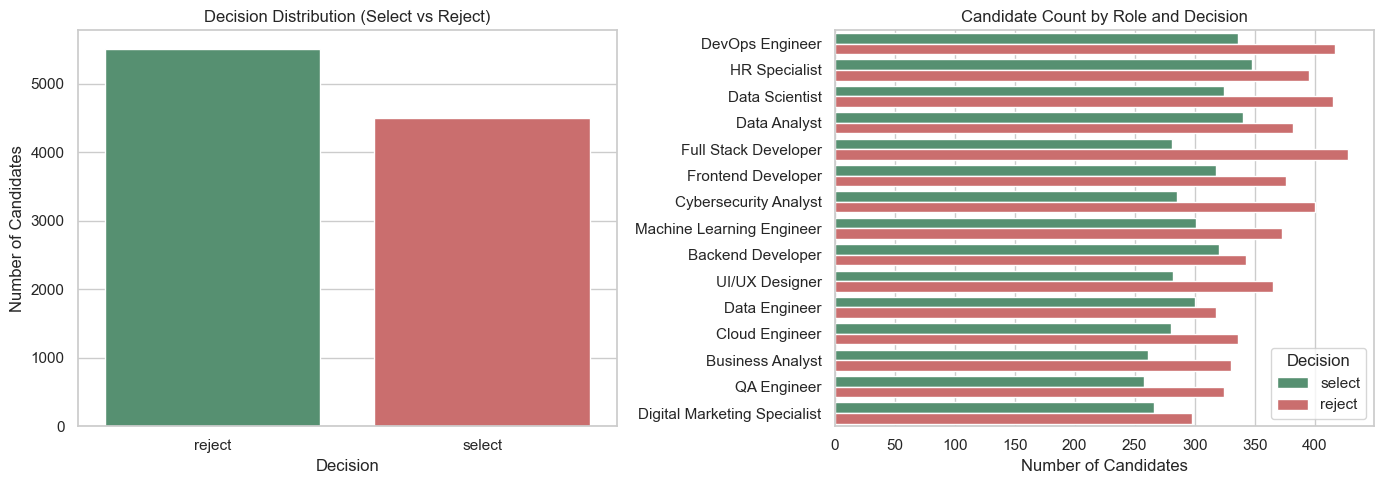

In [4]:
# Figure 1: Target Balance and Job Role Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="Decision", order=["reject", "select"], hue="Decision", palette=["#d95f5f", "#4c9a70"], legend=False, ax=axes[0])
axes[0].set_title("Decision Distribution (Select vs Reject)")
axes[0].set_ylabel("Number of Candidates")

role_order = df["Role"].value_counts().index
sns.countplot(data=df, y="Role", order=role_order, hue="Decision", palette={"reject": "#d95f5f", "select": "#4c9a70"}, ax=axes[1])
axes[1].set_title("Candidate Count by Role and Decision")
axes[1].set_xlabel("Number of Candidates")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

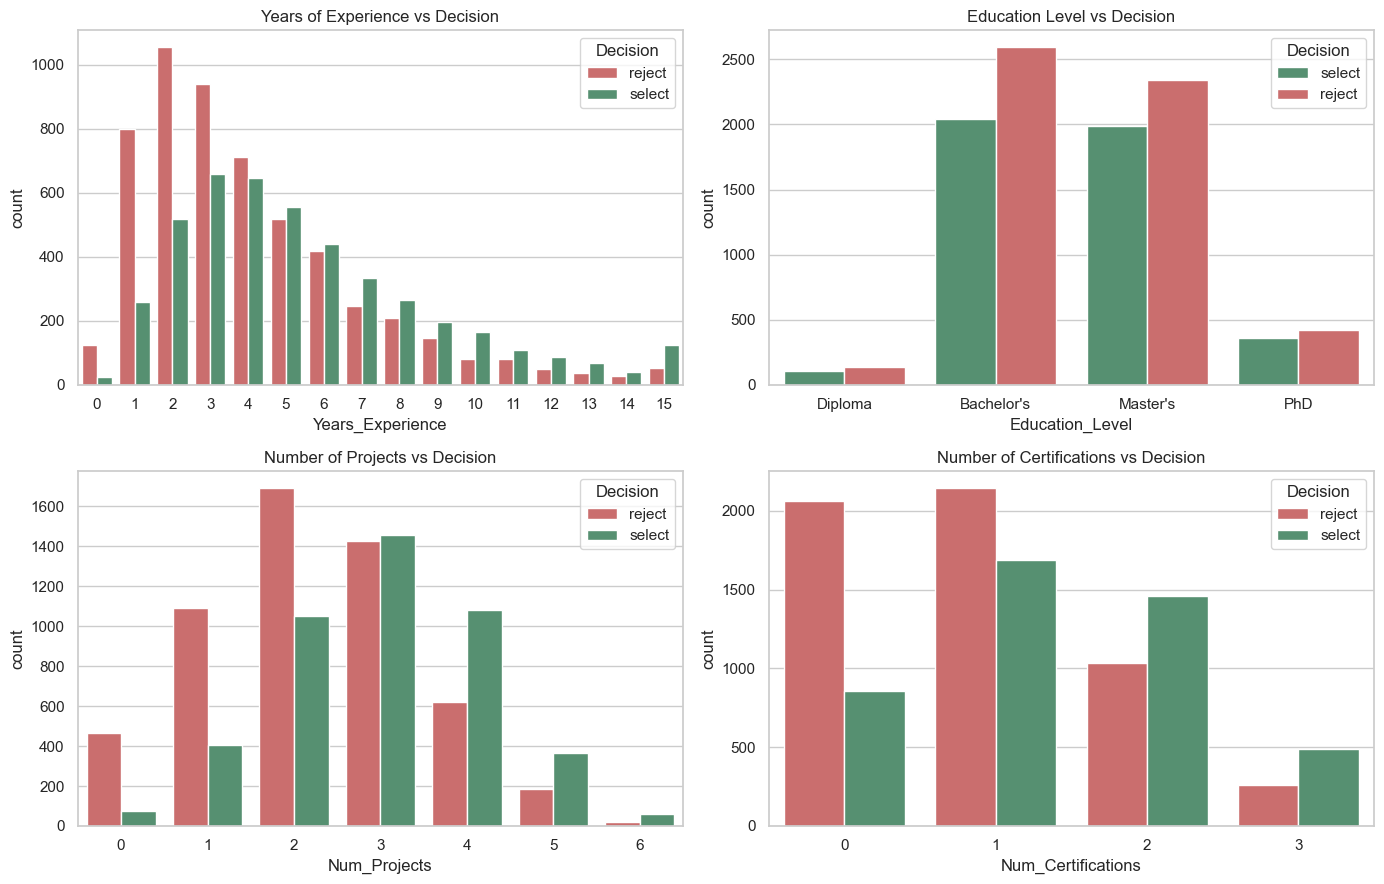

In [5]:
# Figure 2: Experience, Education, Projects, and Certifications vs Decision
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df, x="Years_Experience", hue="Decision", palette={"reject": "#d95f5f", "select": "#4c9a70"}, ax=axes[0, 0])
axes[0, 0].set_title("Years of Experience vs Decision")

edu_order = ["Diploma", "Bachelor's", "Master's", "PhD"]
sns.countplot(data=df, x="Education_Level", order=edu_order, hue="Decision", palette={"reject": "#d95f5f", "select": "#4c9a70"}, ax=axes[0, 1])
axes[0, 1].set_title("Education Level vs Decision")

sns.countplot(data=df, x="Num_Projects", hue="Decision", palette={"reject": "#d95f5f", "select": "#4c9a70"}, ax=axes[1, 0])
axes[1, 0].set_title("Number of Projects vs Decision")

sns.countplot(data=df, x="Num_Certifications", hue="Decision", palette={"reject": "#d95f5f", "select": "#4c9a70"}, ax=axes[1, 1])
axes[1, 1].set_title("Number of Certifications vs Decision")

plt.tight_layout()
plt.show()

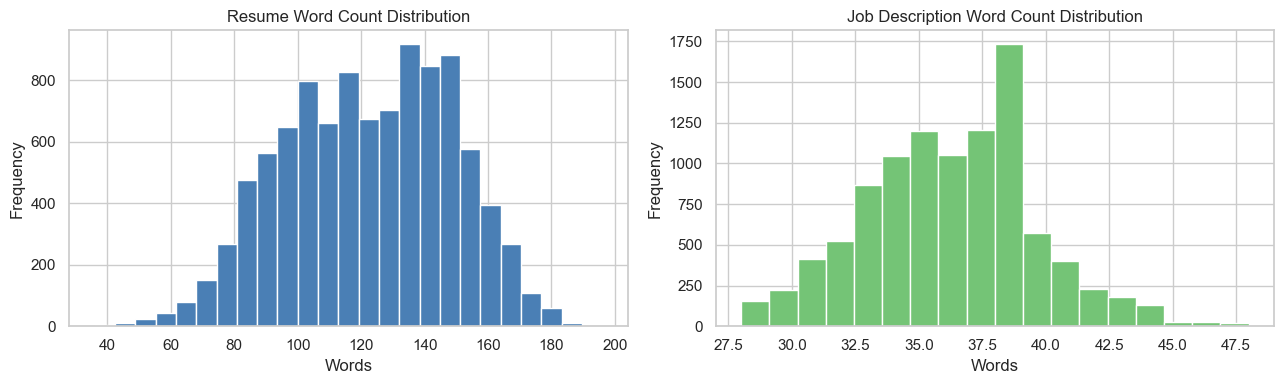

In [6]:
# Figure 3: Resume and Job Description Word Length Distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(resume_words, bins=25, color="#4a7fb5", edgecolor="white")
axes[0].set_title("Resume Word Count Distribution")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Frequency")

axes[1].hist(jd_words, bins=18, color="#74c476", edgecolor="white")
axes[1].set_title("Job Description Word Count Distribution")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [7]:
print("Top 10 Most Common Reasons for Decision:")
for reason, count in df["Reason_for_decision"].value_counts().head(10).items():
    print(f"  ({count}) {reason}")

select_rows = df[df["Decision"] == "select"]
reject_rows = df[df["Decision"] == "reject"]

print("\nRule Pattern Checks:")
print("Select rows mentioning 'Matches ... required skills':", select_rows["Reason_for_decision"].str.contains("Matches").sum(), "/", len(select_rows))
print("Reject rows mentioning 'Missing required skills':", reject_rows["Reason_for_decision"].str.contains("Missing required skills").sum(), "/", len(reject_rows))
print("Reject rows mentioning 'below the ... experience requirement':", reject_rows["Reason_for_decision"].str.contains("below the", case=False).sum())
print("Reject rows mentioning 'not aligned with the role':", reject_rows["Reason_for_decision"].str.contains("not aligned", case=False).sum())
print("Reject rows mentioning 'education below requirement':", reject_rows["Reason_for_decision"].str.contains("education", case=False).sum())

# Check exact threshold for 'strong project portfolio' among selected candidates
strong_portfolio = select_rows["Reason_for_decision"].str.contains("strong project portfolio")
print("\nNum_Projects vs 'strong project portfolio' (among selected candidates):")
print(pd.crosstab(select_rows["Num_Projects"], strong_portfolio))

Top 10 Most Common Reasons for Decision:
  (320) Matches 4 of 4 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (272) Matches 3 of 4 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (247) Matches 5 of 6 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (238) Matches 6 of 7 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (226) Matches 5 of 5 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (217) Matches 4 of 5 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (189) Matches 6 of 6 required skills; meets the experience requirement; relevant role background; strong project portfolio.
  (177) Matches 5 of 7 required skills; meets the experience requirement; rel

In [8]:
print("=== SAMPLE RESUME (Row 0) ===")
print(df.loc[0, "Resume"])

print("\n=== SAMPLE JOB DESCRIPTIONS (First 3 Unique JDs) ===")
for i, jd in enumerate(df["Job_Description"].unique()[:3], 1):
    print(f"{i}. {jd}")

# Check resume sections
sections = ["SUMMARY", "SKILLS", "EXPERIENCE", "EDUCATION", "PROJECTS", "CERTIFICATIONS"]
print("\nResume Section Counts (out of 10,000):")
for sec in sections:
    count = df["Resume"].str.contains(sec).sum()
    print(f"  {sec}: {count}")

# Check if any JD contains an actual responsibilities/duties section
has_resp = df["Job_Description"].str.contains("responsibilit|duties|day-to-day", case=False).sum()
print("\nJob Descriptions containing responsibility/duties statements:", has_resp)

# Common skill synonym/abbreviation pairs discovered in the dataset
skill_synonyms = {
    "amazon web services": "aws",
    "k8s": "kubernetes",
    "js": "javascript",
    "ml": "machine learning",
    "nodejs": "node.js",
    "postgres": "postgresql",
    "powerbi": "power bi",
    "restful services": "rest apis",
    "sklearn": "scikit-learn",
    "search engine optimization": "seo",
    "siem tools": "siem",
    "ci/cd pipelines": "ci/cd",
    "etl pipelines": "etl",
    "google analytics": "ga4",
    "test automation": "automation testing",
    "natural language processing": "nlp",
    "hr information systems": "hris",
    "neural networks": "deep learning",
}
print("Number of key skill synonym pairs identified for Phase 2 normalization:", len(skill_synonyms))

=== SAMPLE RESUME (Row 0) ===
Kavya Smith
Cloud Engineer
Email: kavya.smith@example.com | Phone: +91-9370065534 | linkedin.com/in/kavya-smith

SUMMARY
Detail-oriented Cloud Engineer bringing 7 years of experience in python, azure, linux.

SKILLS
python, azure, linux, networking, terraform, gcp, security, Amazon Web Services, docker

EXPERIENCE
Cloud Engineer, CoreStack (3 years)
- Collaborated with cross-functional teams applying networking across 38 projects.
- Automated recurring tasks using Amazon Web Services, saving about 38 hours per week.
- Automated recurring tasks using linux, saving about 31 hours per week.
Junior Cloud Engineer, Trident Infotech (4 years)
- Led a module built on linux, reducing turnaround time by 43%.
- Automated recurring tasks using gcp, saving about 19 hours per week.

EDUCATION
MCA (2017)

PROJECTS
- Log Monitoring System: built using docker.
- Customer Churn Dashboard: built using docker.
- Campaign Performance Report: built using gcp.

CERTIFICATIONS
-

In [9]:
def clean_text(text):
    # Remove extra spaces and repeated blank lines while keeping technical terms intact
    lines = text.replace("\r\n", "\n").split("\n")
    cleaned_lines = []
    for line in lines:
        cleaned_line = " ".join(line.split())
        if cleaned_line != "":
            cleaned_lines.append(cleaned_line)
        elif len(cleaned_lines) > 0 and cleaned_lines[-1] != "":
            cleaned_lines.append("")
    return "\n".join(cleaned_lines).strip()

df_clean = df.copy()

# Clean text columns cleanly using simple loops / apply
df_clean["Resume"] = df_clean["Resume"].apply(clean_text)

for col in ["Candidate_ID", "Role", "Job_Description", "Education_Level", "Reason_for_decision"]:
    df_clean[col] = df_clean[col].astype(str).str.strip()

df_clean["Decision"] = df_clean["Decision"].str.strip().str.lower()

print("Cleaned DataFrame Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Exact Duplicates:", df_clean.duplicated().sum())
print("\nFirst 6 lines of cleaned Resume (Row 0):")
for line in df_clean.loc[0, "Resume"].split("\n")[:6]:
    print(" ", line)

Cleaned DataFrame Shape:

 (10000, 10)
Total Missing Values: 0
Exact Duplicates: 0

First 6 lines of cleaned Resume (Row 0):
  Kavya Smith
  Cloud Engineer
  Email: kavya.smith@example.com | Phone: +91-9370065534 | linkedin.com/in/kavya-smith
  
  SUMMARY
  Detail-oriented Cloud Engineer bringing 7 years of experience in python, azure, linux.


## Phase 2: Feature Engineering, Regression & Classification Models
Extracts 22 leak-free matching features, constructs a heuristic 0–100 `suitability_score` and 5 `suitability_category` bands, compares 5 regressors and balanced Logistic Regression across 5 `Job_Description`-grouped splits (60:40 to 80:20), and saves `resume_screening_model.pkl` (`CatBoost Regressor`) and `resume_classification_model.pkl` (`Logistic Regression`).

In [10]:
import re
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df_clean exists if someone runs Phase 2 directly
if "df_clean" not in globals():
    df = pd.read_csv("resume_screening_dataset.csv")
    def clean_text(text):
        lines = str(text).replace("\r\n", "\n").split("\n")
        cleaned_lines = []
        for line in lines:
            cleaned_line = " ".join(line.split())
            if cleaned_line != "":
                cleaned_lines.append(cleaned_line)
            elif len(cleaned_lines) > 0 and cleaned_lines[-1] != "":
                cleaned_lines.append("")
        return "\n".join(cleaned_lines).strip()
    df_clean = df.copy()
    df_clean["Resume"] = df_clean["Resume"].apply(clean_text)
    for col in ["Candidate_ID", "Role", "Job_Description", "Education_Level", "Reason_for_decision"]:
        df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean["Decision"] = df_clean["Decision"].str.strip().str.lower()

# Skill synonym dictionary (dataset abbreviations + common tech aliases)
SKILL_SYNONYMS = {
    "ml": "machine learning",
    "nlp": "natural language processing",
    "ai": "artificial intelligence",
    "js": "javascript",
    "amazon web services": "aws",
    "k8s": "kubernetes",
    "nodejs": "node.js",
    "postgres": "postgresql",
    "powerbi": "power bi",
    "restful services": "rest apis",
    "sklearn": "scikit-learn",
    "search engine optimization": "seo",
    "siem tools": "siem",
    "ci/cd pipelines": "ci/cd",
    "etl pipelines": "etl",
    "google analytics": "ga4",
    "test automation": "automation testing",
    "hr information systems": "hris",
    "neural networks": "deep learning",
}

def normalize_skill(skill_text):
    cleaned = skill_text.strip().lower()
    return SKILL_SYNONYMS.get(cleaned, cleaned)

def extract_jd_skills(jd_text):
    req_skills = set()
    pref_skills = set()

    req_markers = ["Key skills:", "hands-on experience in", "skilled in", "You will work with"]
    pref_markers = ["Nice to have:", "Familiarity with", "Bonus points for", "Preferred:"]

    req_part = jd_text
    pref_part = ""
    for pm in pref_markers:
        if pm in jd_text:
            parts = jd_text.split(pm, 1)
            req_part = parts[0]
            pref_part = parts[1]
            break

    for rm in req_markers:
        if rm in req_part:
            raw_req = req_part.split(rm, 1)[1].split(".")[0]
            for item in raw_req.split(","):
                if item.strip():
                    req_skills.add(normalize_skill(item))
            break

    if pref_part:
        raw_pref = pref_part.split(".")[0].replace(" is a plus", "")
        for item in raw_pref.split(","):
            if item.strip():
                pref_skills.add(normalize_skill(item))

    return req_skills, pref_skills

def extract_resume_skills(resume_text, known_skills=None):
    skills = set()
    match = re.search(r"SKILLS\s*\n(.+?)\n\s*\nEXPERIENCE", resume_text, flags=re.S)
    if match:
        for item in match.group(1).split(","):
            if item.strip():
                skills.add(normalize_skill(item))

    if known_skills:
        lower_text = resume_text.lower()
        for raw_skill in known_skills:
            if re.search(r"\b" + re.escape(raw_skill.lower()) + r"\b", lower_text):
                skills.add(normalize_skill(raw_skill))
    return skills

# Build a known-skill vocabulary from dataset JDs & synonyms for Phase 3 fallback scanning
known_skill_set = set(SKILL_SYNONYMS.keys()) | set(SKILL_SYNONYMS.values())
for jd in df_clean["Job_Description"].unique():
    r_set, p_set = extract_jd_skills(jd)
    known_skill_set.update(r_set | p_set)
KNOWN_SKILLS = sorted(known_skill_set)

req_pct_list, pref_pct_list = [], []
matched_req_cnt_list, missing_req_cnt_list, total_matched_list = [], [], []
total_req_list, total_pref_list = [], []
matched_req_text_list, missing_req_text_list = [], []
jd_req_sets, jd_pref_sets = [], []

for idx, row in df_clean.iterrows():
    req_set, pref_set = extract_jd_skills(row["Job_Description"])
    res_set = extract_resume_skills(row["Resume"])

    # Sets prevent double-counting synonyms
    matched_req = sorted(res_set.intersection(req_set))
    missing_req = sorted(req_set.difference(res_set))
    matched_pref = sorted(res_set.intersection(pref_set))

    total_req = len(req_set)
    total_pref = len(pref_set)

    req_pct = (len(matched_req) / total_req * 100.0) if total_req > 0 else 0.0
    pref_pct = (len(matched_pref) / total_pref * 100.0) if total_pref > 0 else 0.0

    req_pct_list.append(round(req_pct, 2))
    pref_pct_list.append(round(pref_pct, 2))
    matched_req_cnt_list.append(len(matched_req))
    missing_req_cnt_list.append(len(missing_req))
    total_matched_list.append(len(matched_req) + len(matched_pref))
    total_req_list.append(total_req)
    total_pref_list.append(total_pref)
    matched_req_text_list.append(", ".join(matched_req))
    missing_req_text_list.append(", ".join(missing_req))
    jd_req_sets.append(req_set)
    jd_pref_sets.append(pref_set)

df_feat = df_clean.copy()
df_feat["req_skill_match_pct"] = req_pct_list
df_feat["pref_skill_match_pct"] = pref_pct_list
df_feat["matched_req_skills_count"] = matched_req_cnt_list
df_feat["missing_req_skills_count"] = missing_req_cnt_list
df_feat["total_matched_skills"] = total_matched_list
df_feat["total_req_skills"] = total_req_list
df_feat["total_pref_skills"] = total_pref_list
df_feat["matched_req_skills"] = matched_req_text_list
df_feat["missing_req_skills"] = missing_req_text_list

display(df_feat[[
    "Role", "req_skill_match_pct", "pref_skill_match_pct",
    "matched_req_skills_count", "missing_req_skills_count",
    "total_matched_skills", "matched_req_skills", "missing_req_skills"
]].head(5))

,Role,req_skill_match_pct,pref_skill_match_pct,matched_req_skills_count,missing_req_skills_count,total_matched_skills,matched_req_skills,missing_req_skills
0,Cloud Engineer,85.71,33.33,6,1,7,"aws, azure, linux, networking, python, terraform",kubernetes
1,Full Stack Developer,50.00,0.00,3,3,3,"node.js, react, sql","css, git, rest apis"
2,DevOps Engineer,25.00,100.00,1,3,2,git,"aws, kubernetes, monitoring"
3,Backend Developer,100.00,33.33,4,0,5,"git, java, postgresql, rest apis",
4,Cybersecurity Analyst,50.00,50.00,3,3,4,"linux, penetration testing, siem","firewalls, incident response, risk assessment"


In [11]:
EDU_RANK_MAP = {"Diploma": 1, "Bachelor's": 2, "Master's": 3, "PhD": 4}

def extract_required_experience(jd_text):
    if "fresher-level" in jd_text.lower():
        return 0
    match = re.search(r"(\d+)\+\s*years", jd_text.lower())
    return int(match.group(1)) if match else 0

def extract_required_education(jd_text):
    for degree_name in ["PhD", "Master's", "Bachelor's", "Diploma"]:
        if degree_name in jd_text:
            return EDU_RANK_MAP[degree_name]
    return 2

def extract_resume_role(resume_text):
    lines = [line.strip() for line in resume_text.split("\n") if line.strip()]
    return lines[1] if len(lines) > 1 else ""

def get_section_lines(resume_text, section_name, next_section=None):
    if section_name not in resume_text:
        return []
    part = resume_text.split(section_name, 1)[1]
    if next_section and next_section in part:
        part = part.split(next_section, 1)[0]
    return [line.strip() for line in part.split("\n") if line.strip().startswith("-")]

# Experience and role alignment
df_feat["candidate_experience"] = df_feat["Years_Experience"]
df_feat["required_experience"] = df_feat["Job_Description"].apply(extract_required_experience)
df_feat["experience_diff"] = df_feat["candidate_experience"] - df_feat["required_experience"]
df_feat["meets_experience"] = (df_feat["candidate_experience"] >= df_feat["required_experience"]).astype(int)
df_feat["role_aligned"] = (df_feat["Resume"].apply(extract_resume_role) == df_feat["Role"]).astype(int)

# Education features
df_feat["candidate_edu_level"] = df_feat["Education_Level"].map(EDU_RANK_MAP)
df_feat["required_edu_level"] = df_feat["Job_Description"].apply(extract_required_education)
df_feat["meets_education"] = (df_feat["candidate_edu_level"] >= df_feat["required_edu_level"]).astype(int)

edu_suit_list = []
for cand_lvl, req_lvl in zip(df_feat["candidate_edu_level"], df_feat["required_edu_level"]):
    if cand_lvl >= req_lvl:
        edu_suit_list.append(1.0)
    elif cand_lvl == req_lvl - 1:
        edu_suit_list.append(0.5)
    else:
        edu_suit_list.append(0.0)
df_feat["edu_suitability"] = edu_suit_list

# Project and certification features
rel_proj_counts, rel_proj_ratios, rel_cert_counts = [], [], []
stop_words = {"certified", "certificate", "fundamentals", "associate", "professional", "and", "in", "for", "of"}

for idx, row in df_feat.iterrows():
    jd_skills_all = jd_req_sets[idx] | jd_pref_sets[idx]
    jd_words_set = set(re.findall(r"[a-z0-9\+\#\.]+", row["Job_Description"].lower()))

    proj_lines = get_section_lines(row["Resume"], "PROJECTS", "CERTIFICATIONS")
    matched_proj = 0
    for line in proj_lines:
        line_lower = line.lower()
        found = any(sk in line_lower for sk in jd_skills_all)
        if not found:
            found = any(canon in jd_skills_all and alias in line_lower for alias, canon in SKILL_SYNONYMS.items())
        if found:
            matched_proj += 1

    total_p = row["Num_Projects"]
    rel_proj_counts.append(matched_proj)
    rel_proj_ratios.append(round(matched_proj / total_p, 3) if total_p > 0 else 0.0)

    cert_lines = get_section_lines(row["Resume"], "CERTIFICATIONS")
    matched_cert = 0
    for line in cert_lines:
        cert_tokens = set(re.findall(r"[a-z0-9\+\#\.]+", line.lower())) - stop_words
        if len(cert_tokens.intersection(jd_words_set)) > 0:
            matched_cert += 1
    rel_cert_counts.append(matched_cert)

df_feat["num_projects"] = df_feat["Num_Projects"]
df_feat["num_certifications"] = df_feat["Num_Certifications"]
df_feat["relevant_projects_count"] = rel_proj_counts
df_feat["project_relevance_ratio"] = rel_proj_ratios
df_feat["relevant_certs_count"] = rel_cert_counts

display(df_feat[[
    "candidate_experience", "required_experience", "experience_diff", "meets_experience",
    "role_aligned", "edu_suitability", "num_projects", "relevant_projects_count",
    "project_relevance_ratio", "num_certifications", "relevant_certs_count"
]].head(5))

,candidate_experience,required_experience,experience_diff,meets_experience,role_aligned,edu_suitability,num_projects,relevant_projects_count,project_relevance_ratio,num_certifications,relevant_certs_count
0,7,3,4,1,1,1.0,3,1,0.333,3,2
1,9,3,6,1,1,1.0,4,3,0.750,1,1
2,1,2,-1,0,0,1.0,4,2,0.500,0,0
3,6,3,3,1,1,1.0,4,1,0.250,2,1
4,3,3,0,1,1,1.0,2,2,1.000,0,0


Heuristic Suitability Score Summary:


count    10000.00
mean        59.80
std         16.86
min          7.47
25%         47.41
50%         61.21
75%         72.69
max         93.57
Name: suitability_score, dtype: float64


Suitability Category Distribution (Class Imbalance Check):


,Count,Percent (%)
suitability_category,,
Very Poor,49,0.49
Poor,1442,14.42
Moderate,3269,32.69
Good,4034,40.34
Excellent,1206,12.06


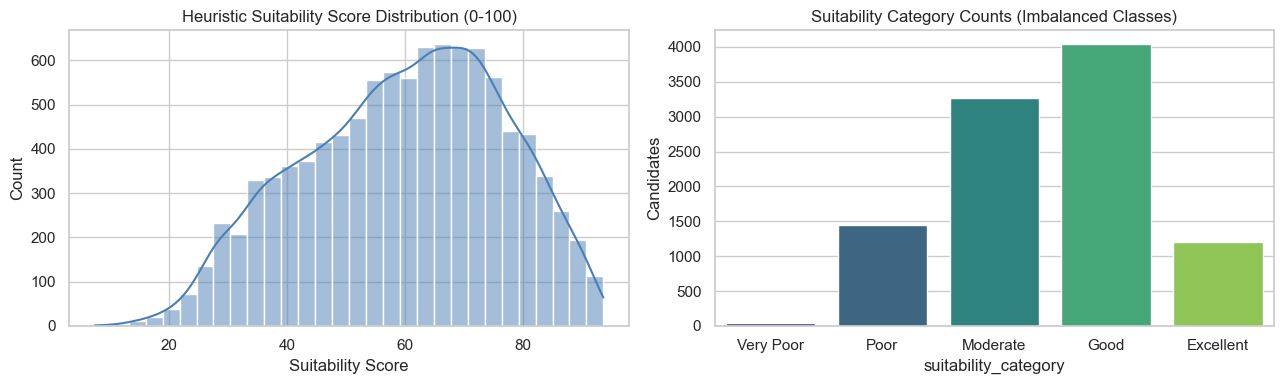

In [12]:
def compute_row_jaccard_similarity(resume_text, jd_text):
    res_tokens = set(re.findall(r"[a-z0-9\+\#\.]{2,}", resume_text.lower()))
    jd_tokens = set(re.findall(r"[a-z0-9\+\#\.]{2,}", jd_text.lower()))
    if not res_tokens or not jd_tokens:
        return 0.0
    jaccard = len(res_tokens.intersection(jd_tokens)) / len(res_tokens.union(jd_tokens))
    return min(jaccard * 2.5, 1.0) * 100.0

target_scores = []
for idx, row in df_feat.iterrows():
    comp_req = row["req_skill_match_pct"]
    comp_pref = row["pref_skill_match_pct"]

    if row["experience_diff"] >= 0:
        exp_sub = 100.0
    else:
        exp_sub = max(0.0, 100.0 + row["experience_diff"] * 25.0)
    role_sub = 100.0 if row["role_aligned"] == 1 else 0.0
    comp_exp = 0.70 * exp_sub + 0.30 * role_sub

    comp_edu = row["edu_suitability"] * 100.0

    comp_proj_cert = (
        (min(row["num_projects"], 4) / 4.0) * 40.0
        + (min(row["relevant_projects_count"], 3) / 3.0) * 30.0
        + (min(row["num_certifications"], 3) / 3.0) * 15.0
        + (min(row["relevant_certs_count"], 2) / 2.0) * 15.0
    )

    comp_text = compute_row_jaccard_similarity(row["Resume"], row["Job_Description"])

    total_score = (
        0.35 * comp_req
        + 0.15 * comp_pref
        + 0.20 * comp_exp
        + 0.10 * comp_edu
        + 0.10 * comp_proj_cert
        + 0.10 * comp_text
    )
    target_scores.append(round(float(np.clip(total_score, 0.0, 100.0)), 2))

df_feat["suitability_score"] = target_scores

CATEGORY_LABELS = ["Very Poor", "Poor", "Moderate", "Good", "Excellent"]
SCORE_BINS = [-0.01, 20.0, 40.0, 60.0, 80.0, 100.0]
df_feat["suitability_category"] = pd.cut(
    df_feat["suitability_score"], bins=SCORE_BINS, labels=CATEGORY_LABELS
)

print("Heuristic Suitability Score Summary:")
display(df_feat["suitability_score"].describe().round(2))

print("\nSuitability Category Distribution (Class Imbalance Check):")
cat_counts = df_feat["suitability_category"].value_counts().reindex(CATEGORY_LABELS)
cat_pct = (cat_counts / len(df_feat) * 100).round(2)
display(pd.DataFrame({"Count": cat_counts, "Percent (%)": cat_pct}))

# Visualize heuristic score and category counts
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_feat["suitability_score"], bins=30, kde=True, color="#4a7fb5", ax=axes[0])
axes[0].set_title("Heuristic Suitability Score Distribution (0-100)")
axes[0].set_xlabel("Suitability Score")

sns.barplot(x=cat_counts.index, y=cat_counts.values, hue=cat_counts.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Suitability Category Counts (Imbalanced Classes)")
axes[1].set_ylabel("Candidates")
plt.tight_layout()
plt.show()

In [13]:
base_feature_cols = [
    "req_skill_match_pct",
    "pref_skill_match_pct",
    "matched_req_skills_count",
    "missing_req_skills_count",
    "total_matched_skills",
    "total_req_skills",
    "total_pref_skills",
    "candidate_experience",
    "required_experience",
    "experience_diff",
    "meets_experience",
    "role_aligned",
    "candidate_edu_level",
    "required_edu_level",
    "meets_education",
    "edu_suitability",
    "num_projects",
    "relevant_projects_count",
    "project_relevance_ratio",
    "num_certifications",
    "relevant_certs_count",
]

forbidden = {"Candidate_ID", "Reason_for_decision", "Decision", "suitability_score", "suitability_category"}
assert forbidden.isdisjoint(set(base_feature_cols)), "Leakage column detected!"

X_base = df_feat[base_feature_cols].copy()
y_reg = df_feat["suitability_score"].copy()
y_cls = df_feat["suitability_category"].astype(str).copy()

print("Legitimate base features:", len(base_feature_cols))
display(X_base.head(5))

Legitimate base features: 21


,req_skill_match_pct,pref_skill_match_pct,matched_req_skills_count,missing_req_skills_count,total_matched_skills,total_req_skills,total_pref_skills,candidate_experience,required_experience,experience_diff,...,role_aligned,candidate_edu_level,required_edu_level,meets_education,edu_suitability,num_projects,relevant_projects_count,project_relevance_ratio,num_certifications,relevant_certs_count
0,85.71,33.33,6,1,7,7,3,7,3,4,...,1,3,2,1,1.0,3,1,0.333,3,2
1,50.00,0.00,3,3,3,6,2,9,3,6,...,1,3,2,1,1.0,4,3,0.750,1,1
2,25.00,100.00,1,3,2,4,1,1,2,-1,...,0,3,2,1,1.0,4,2,0.500,0,0
3,100.00,33.33,4,0,5,4,3,6,3,3,...,1,3,3,1,1.0,4,1,0.250,2,1
4,50.00,50.00,3,3,4,6,2,3,3,0,...,1,3,2,1,1.0,2,2,1.000,0,0


In [14]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import LinearSVR
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score, ndcg_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from scipy.stats import spearmanr

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
    print("XGBoost available.")
except ImportError as err:
    HAS_XGB = False
    print("XGBoost NOT available:", err)

try:
    from catboost import CatBoostRegressor
    HAS_CAT = True
    print("CatBoost available.")
except ImportError as err:
    HAS_CAT = False
    print("CatBoost NOT available:", err)

def compute_split_tfidf_cosine(train_res, train_jd, test_res, test_jd):
    # Fit TF-IDF strictly on training data to prevent leakage
    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000,
        token_pattern=r"(?u)\b\w[\w\+\#\.\/-]*"
    )
    vectorizer.fit(pd.concat([train_res, train_jd], ignore_index=True))

    def rowwise_cosine(res_series, jd_series):
        m_res = vectorizer.transform(res_series)
        m_jd = vectorizer.transform(jd_series)
        return np.asarray(m_res.multiply(m_jd).sum(axis=1)).ravel()

    return rowwise_cosine(train_res, train_jd), rowwise_cosine(test_res, test_jd), vectorizer

def evaluate_within_jd_ranking(test_jds, y_true_vals, y_pred_vals):
    eval_df = pd.DataFrame({"jd": test_jds.values, "y_true": y_true_vals, "y_pred": y_pred_vals})
    spearman_list, ndcg5_list, ndcg10_list = [], [], []
    for _, grp in eval_df.groupby("jd"):
        if len(grp) < 2:
            continue
        yt = grp["y_true"].values
        yp = grp["y_pred"].values
        corr, _ = spearmanr(yt, yp)
        if not np.isnan(corr):
            spearman_list.append(corr)
        yt_pos = np.clip(yt, 0.0, None).reshape(1, -1)
        yp_arr = yp.reshape(1, -1)
        ndcg5_list.append(ndcg_score(yt_pos, yp_arr, k=5))
        ndcg10_list.append(ndcg_score(yt_pos, yp_arr, k=10))
    return float(np.mean(spearman_list)), float(np.mean(ndcg5_list)), float(np.mean(ndcg10_list))

def build_regressors():
    models = {
        "Decision Tree Regressor": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=42),
        "Random Forest Regressor": RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=1),
        "Linear SVR": Pipeline([("scaler", StandardScaler()), ("model", LinearSVR(C=1.0, max_iter=5000, random_state=42))]),
    }
    if HAS_XGB:
        models["XGBoost Regressor"] = XGBRegressor(
            n_estimators=150, max_depth=5, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=1
        )
    if HAS_CAT:
        models["CatBoost Regressor"] = CatBoostRegressor(
            iterations=200, depth=6, learning_rate=0.1,
            random_seed=42, verbose=0, allow_writing_files=False
        )
    return models

split_configs = [
    ("60:40", 0.40),
    ("65:35", 0.35),
    ("70:30", 0.30),
    ("75:25", 0.25),
    ("80:20", 0.20),
]

reg_results = []
cls_results = []
split_summary_rows = []
last_80_20_cls_artifacts = {}

for ratio_label, test_size in split_configs:
    t_split = time.time()
    print(f"Running split {ratio_label}...", flush=True)

    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=42)
    train_idx, test_idx = next(gss.split(X_base, y_reg, groups=df_feat["Job_Description"]))

    cand_overlap = len(set(df_feat.iloc[train_idx]["Candidate_ID"]) & set(df_feat.iloc[test_idx]["Candidate_ID"]))
    jd_overlap = len(set(df_feat.iloc[train_idx]["Job_Description"]) & set(df_feat.iloc[test_idx]["Job_Description"]))

    # Fit TF-IDF on training data only
    tr_tfidf, te_tfidf, split_vec = compute_split_tfidf_cosine(
        df_feat.iloc[train_idx]["Resume"], df_feat.iloc[train_idx]["Job_Description"],
        df_feat.iloc[test_idx]["Resume"], df_feat.iloc[test_idx]["Job_Description"]
    )

    X_train = X_base.iloc[train_idx].copy()
    X_test = X_base.iloc[test_idx].copy()
    X_train["tfidf_cosine_sim"] = tr_tfidf
    X_test["tfidf_cosine_sim"] = te_tfidf

    y_tr_reg = y_reg.iloc[train_idx].values
    y_te_reg = y_reg.iloc[test_idx].values
    y_tr_cls = y_cls.iloc[train_idx].values
    y_te_cls = y_cls.iloc[test_idx].values
    test_jds = df_feat.iloc[test_idx]["Job_Description"]

    # Check class distribution in each split
    missing_tr = sorted(set(CATEGORY_LABELS) - set(y_tr_cls))
    missing_te = sorted(set(CATEGORY_LABELS) - set(y_te_cls))

    split_summary_rows.append({
        "Train/Test Ratio": ratio_label,
        "Train Rows": len(train_idx),
        "Test Rows": len(test_idx),
        "Train JDs": df_feat.iloc[train_idx]["Job_Description"].nunique(),
        "Test JDs": df_feat.iloc[test_idx]["Job_Description"].nunique(),
        "JD Overlap": jd_overlap,
        "Candidate Overlap": cand_overlap,
        "Missing Train Classes": ", ".join(missing_tr) if missing_tr else "None",
        "Missing Test Classes": ", ".join(missing_te) if missing_te else "None",
    })

    # 1) Five Regression Models
    for model_name, model in build_regressors().items():
        model.fit(X_train, y_tr_reg)
        y_pred_reg = np.clip(model.predict(X_test), 0.0, 100.0)

        mae = mean_absolute_error(y_te_reg, y_pred_reg)
        rmse = root_mean_squared_error(y_te_reg, y_pred_reg)
        r2 = r2_score(y_te_reg, y_pred_reg)
        sp, ndcg5, ndcg10 = evaluate_within_jd_ranking(test_jds, y_te_reg, y_pred_reg)

        reg_results.append({
            "Model": model_name,
            "Train/Test Ratio": ratio_label,
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4),
            "R2": round(r2, 4),
            "Within-JD Spearman": round(sp, 4),
            "NDCG@5": round(ndcg5, 4),
            "NDCG@10": round(ndcg10, 4),
        })

    # 2) Separate Logistic Regression Classification Experiment
    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])
    clf.fit(X_train, y_tr_cls)
    y_pred_cls = clf.predict(X_test)

    cls_results.append({
        "Model": "Logistic Regression (Balanced)",
        "Train/Test Ratio": ratio_label,
        "Accuracy": round(accuracy_score(y_te_cls, y_pred_cls), 4),
        "Precision Macro": round(precision_score(y_te_cls, y_pred_cls, average="macro", zero_division=0), 4),
        "Recall Macro": round(recall_score(y_te_cls, y_pred_cls, average="macro", zero_division=0), 4),
        "F1 Macro": round(f1_score(y_te_cls, y_pred_cls, average="macro", zero_division=0), 4),
        "Precision Weighted": round(precision_score(y_te_cls, y_pred_cls, average="weighted", zero_division=0), 4),
        "Recall Weighted": round(recall_score(y_te_cls, y_pred_cls, average="weighted", zero_division=0), 4),
        "F1 Weighted": round(f1_score(y_te_cls, y_pred_cls, average="weighted", zero_division=0), 4),
    })

    if ratio_label == "80:20":
        last_80_20_cls_artifacts = {
            "clf": clf,
            "vectorizer": split_vec,
            "feature_columns": list(X_train.columns),
            "y_test": y_te_cls,
            "y_pred": y_pred_cls,
        }

    print(f"  Completed {ratio_label} in {time.time() - t_split:.1f}s", flush=True)

split_summary_df = pd.DataFrame(split_summary_rows)
reg_results_df = pd.DataFrame(reg_results)
cls_results_df = pd.DataFrame(cls_results)

print("\n=== Grouped Split Verification (Zero JD & Candidate Overlap) ===")
display(split_summary_df)

print("\n=== Regression Model Comparison Table (5 Regressors x 5 Splits) ===")
display(reg_results_df)

print("\n=== Logistic Regression Classification Comparison Table (5 Splits) ===")
display(cls_results_df)

XGBoost available.
CatBoost available.
Running split 60:40...


  Completed 60:40 in 11.8s


Running split 65:35...


  Completed 65:35 in 11.1s


Running split 70:30...


  Completed 70:30 in 10.8s


... (6 outputs left out)


=== Regression Model Comparison Table (5 Regressors x 5 Splits) ===


,Model,Train/Test Ratio,MAE,RMSE,R2,Within-JD Spearman,NDCG@5,NDCG@10
0,Decision Tree Regressor,60:40,2.2636,3.0555,0.9667,0.9489,0.9975,0.9985
1,Random Forest Regressor,60:40,1.2297,1.8427,0.9879,0.9744,0.9993,0.9996
2,Linear SVR,60:40,0.9189,1.6720,0.9900,0.9785,0.9994,0.9997
3,XGBoost Regressor,60:40,0.4972,0.6790,0.9984,0.9901,0.9999,0.9999
4,CatBoost Regressor,60:40,0.3458,0.4770,0.9992,0.9925,0.9999,1.0000
5,Decision Tree Regressor,65:35,2.2971,3.0750,0.9662,0.9469,0.9973,0.9984
6,Random Forest Regressor,65:35,1.2315,1.8656,0.9875,0.9738,0.9993,0.9996
7,Linear SVR,65:35,0.9206,1.6769,0.9899,0.9785,0.9994,0.9996
8,XGBoost Regressor,65:35,0.5079,0.6934,0.9983,0.9899,0.9999,0.9999
9,CatBoost Regressor,65:35,0.3438,0.4631,0.9992,0.9927,1.0000,1.0000



=== Logistic Regression Classification Comparison Table (5 Splits) ===


,Model,Train/Test Ratio,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted
0,Logistic Regression (Balanced),60:40,0.9371,0.8748,0.9477,0.9061,0.9401,0.9371,0.9376
1,Logistic Regression (Balanced),65:35,0.9367,0.8735,0.9476,0.9053,0.9399,0.9367,0.9372
2,Logistic Regression (Balanced),70:30,0.9378,0.8833,0.9579,0.9155,0.9407,0.9378,0.9382
3,Logistic Regression (Balanced),75:25,0.9446,0.8885,0.9615,0.9199,0.9471,0.9446,0.9451
4,Logistic Regression (Balanced),80:20,0.9452,0.9173,0.9620,0.9380,0.9475,0.9452,0.9455


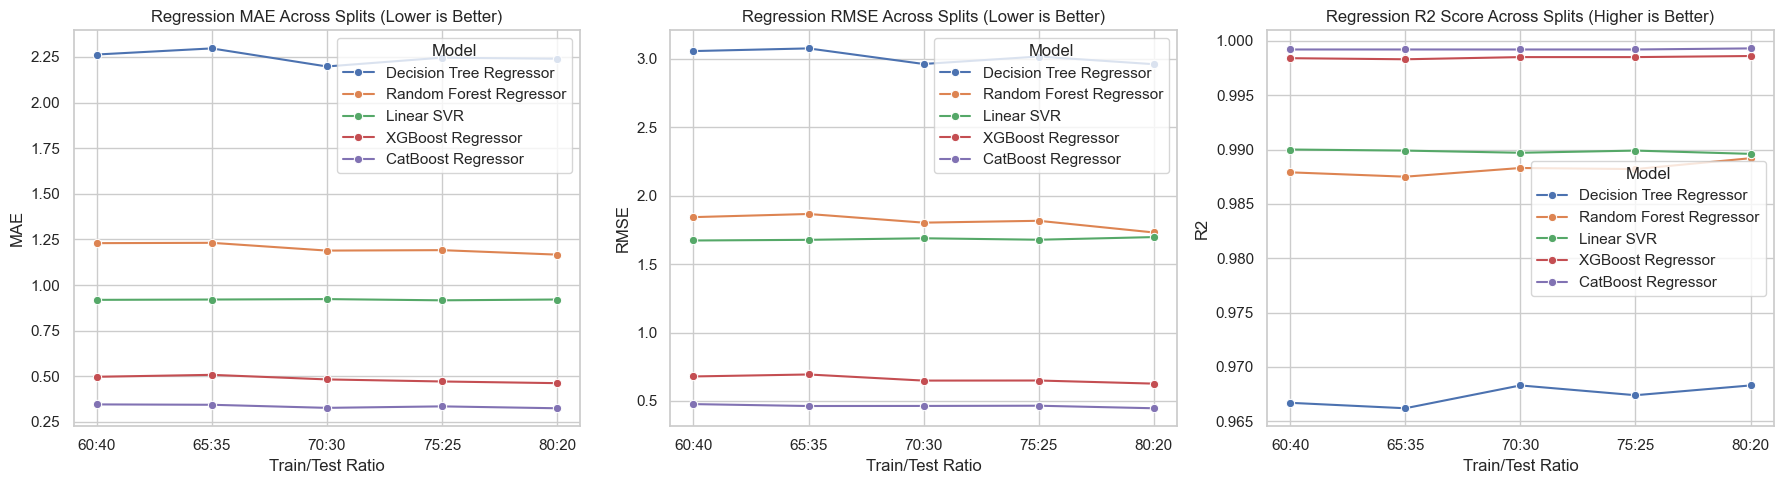

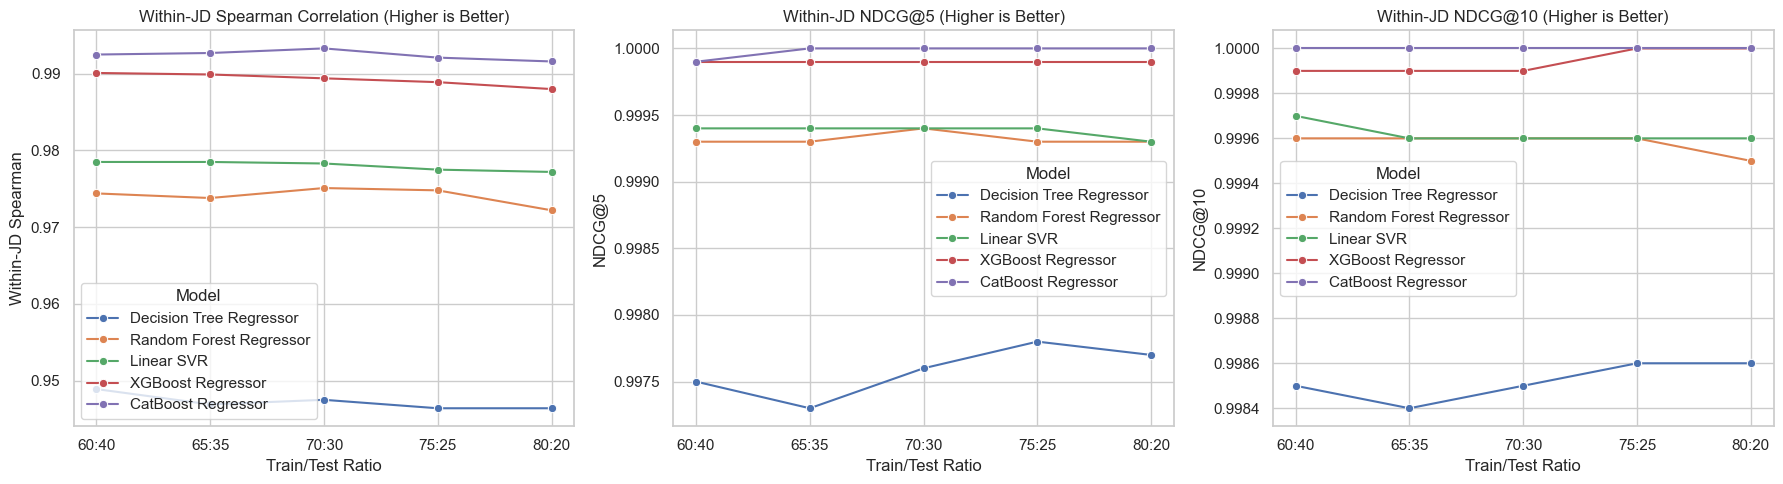

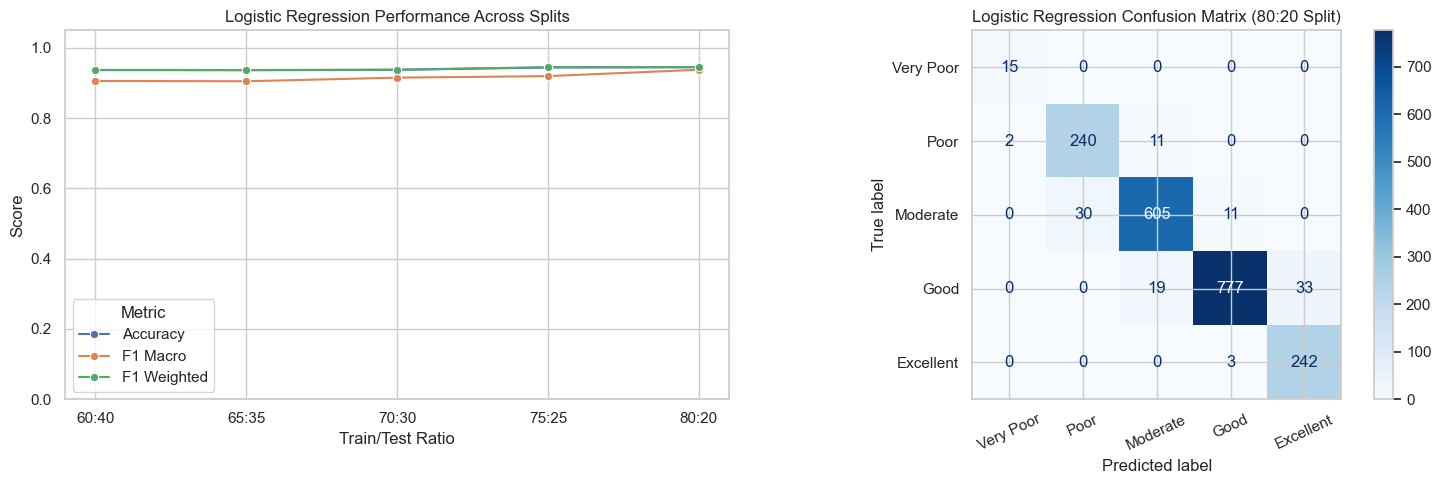

=== Logistic Regression Classification Report (80:20 Split) ===
              precision    recall  f1-score   support

   Very Poor       0.88      1.00      0.94        15
        Poor       0.89      0.95      0.92       253
    Moderate       0.95      0.94      0.94       646
        Good       0.98      0.94      0.96       829
   Excellent       0.88      0.99      0.93       245

    accuracy                           0.95      1988
   macro avg       0.92      0.96      0.94      1988
weighted avg       0.95      0.95      0.95      1988



In [15]:
# Figure 1: Regression Error (MAE & RMSE) and R2 Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="MAE", hue="Model", marker="o", ax=axes[0])
axes[0].set_title("Regression MAE Across Splits (Lower is Better)")

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="RMSE", hue="Model", marker="o", ax=axes[1])
axes[1].set_title("Regression RMSE Across Splits (Lower is Better)")

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="R2", hue="Model", marker="o", ax=axes[2])
axes[2].set_title("Regression R2 Score Across Splits (Higher is Better)")

plt.tight_layout()
plt.show()

# Figure 2: Ranking Metrics Comparison (Spearman, NDCG@5, NDCG@10)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="Within-JD Spearman", hue="Model", marker="o", ax=axes[0])
axes[0].set_title("Within-JD Spearman Correlation (Higher is Better)")

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="NDCG@5", hue="Model", marker="o", ax=axes[1])
axes[1].set_title("Within-JD NDCG@5 (Higher is Better)")

sns.lineplot(data=reg_results_df, x="Train/Test Ratio", y="NDCG@10", hue="Model", marker="o", ax=axes[2])
axes[2].set_title("Within-JD NDCG@10 (Higher is Better)")

plt.tight_layout()
plt.show()

# Figure 3: Logistic Regression Performance + 80:20 Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cls_melt = cls_results_df.melt(
    id_vars=["Train/Test Ratio"],
    value_vars=["Accuracy", "F1 Macro", "F1 Weighted"],
    var_name="Metric", value_name="Score"
)
sns.lineplot(data=cls_melt, x="Train/Test Ratio", y="Score", hue="Metric", marker="o", ax=axes[0])
axes[0].set_title("Logistic Regression Performance Across Splits")
axes[0].set_ylim(0, 1.05)

cm = confusion_matrix(
    last_80_20_cls_artifacts["y_test"],
    last_80_20_cls_artifacts["y_pred"],
    labels=CATEGORY_LABELS
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CATEGORY_LABELS)
disp.plot(ax=axes[1], cmap="Blues", values_format="d")
axes[1].set_title("Logistic Regression Confusion Matrix (80:20 Split)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

print("=== Logistic Regression Classification Report (80:20 Split) ===")
print(classification_report(
    last_80_20_cls_artifacts["y_test"],
    last_80_20_cls_artifacts["y_pred"],
    labels=CATEGORY_LABELS,
    zero_division=0
))

In [16]:
reg_summary_df = reg_results_df.groupby("Model").agg(
    Mean_MAE=("MAE", "mean"),
    Mean_RMSE=("RMSE", "mean"),
    Std_RMSE=("RMSE", "std"),
    Mean_R2=("R2", "mean"),
    Mean_Spearman=("Within-JD Spearman", "mean"),
    Mean_NDCG5=("NDCG@5", "mean"),
    Mean_NDCG10=("NDCG@10", "mean"),
).round(4).sort_values("Mean_RMSE")

print("=== Regression Summary Across All 5 Splits ===")
display(reg_summary_df)

# Balanced multi-metric ranking (never pick using just one metric)
rank_table = pd.DataFrame({
    "mae_rank": reg_summary_df["Mean_MAE"].rank(ascending=True),
    "rmse_rank": reg_summary_df["Mean_RMSE"].rank(ascending=True),
    "r2_rank": reg_summary_df["Mean_R2"].rank(ascending=False),
    "spearman_rank": reg_summary_df["Mean_Spearman"].rank(ascending=False),
    "ndcg5_rank": reg_summary_df["Mean_NDCG5"].rank(ascending=False),
    "stability_rank": reg_summary_df["Std_RMSE"].rank(ascending=True),
})
rank_table["avg_rank"] = rank_table.mean(axis=1)
selected_reg_name = rank_table["avg_rank"].idxmin()

print("=== Balanced Regression Model Ranking ===")
display(rank_table.sort_values("avg_rank").round(2))
print(f"\n>>> SELECTED REGRESSION MODEL: {selected_reg_name} <<<")

# Refit selected regressor on the 80:20 training split ONLY (no test data used)
gss_80 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr_80_idx, te_80_idx = next(gss_80.split(X_base, y_reg, groups=df_feat["Job_Description"]))

tr_80_tfidf, _, final_vectorizer = compute_split_tfidf_cosine(
    df_feat.iloc[tr_80_idx]["Resume"], df_feat.iloc[tr_80_idx]["Job_Description"],
    df_feat.iloc[te_80_idx]["Resume"], df_feat.iloc[te_80_idx]["Job_Description"]
)

X_final_tr = X_base.iloc[tr_80_idx].copy()
X_final_tr["tfidf_cosine_sim"] = tr_80_tfidf
y_final_tr_reg = y_reg.iloc[tr_80_idx].values

final_reg_model = build_regressors()[selected_reg_name]
final_reg_model.fit(X_final_tr, y_final_tr_reg)

reg_bundle = {
    "model_name": selected_reg_name,
    "model": final_reg_model,
    "tfidf_vectorizer": final_vectorizer,
    "feature_columns": list(X_final_tr.columns),
    "skill_synonyms": SKILL_SYNONYMS,
    "known_skills": KNOWN_SKILLS,
    "edu_rank_map": EDU_RANK_MAP,
}
joblib.dump(reg_bundle, "resume_screening_model.pkl")

cls_bundle = {
    "model_name": "Logistic Regression (Balanced)",
    "model": last_80_20_cls_artifacts["clf"],
    "tfidf_vectorizer": last_80_20_cls_artifacts["vectorizer"],
    "feature_columns": last_80_20_cls_artifacts["feature_columns"],
    "category_labels": CATEGORY_LABELS,
    "score_bins": SCORE_BINS,
    "skill_synonyms": SKILL_SYNONYMS,
    "known_skills": KNOWN_SKILLS,
    "edu_rank_map": EDU_RANK_MAP,
}
joblib.dump(cls_bundle, "resume_classification_model.pkl")

print("Saved regression model bundle -> resume_screening_model.pkl")
print("Saved classification model bundle -> resume_classification_model.pkl")

=== Regression Summary Across All 5 Splits ===


,Mean_MAE,Mean_RMSE,Std_RMSE,Mean_R2,Mean_Spearman,Mean_NDCG5,Mean_NDCG10
Model,,,,,,,
CatBoost Regressor,0.3352,0.4631,0.0108,0.9992,0.9924,1.0000,1.0000
XGBoost Regressor,0.4843,0.6594,0.0266,0.9985,0.9893,0.9999,0.9999
Linear SVR,0.9199,1.6823,0.0101,0.9898,0.9780,0.9994,0.9996
Random Forest Regressor,1.2016,1.8115,0.0513,0.9882,0.9741,0.9993,0.9996
Decision Tree Regressor,2.2491,3.0134,0.0529,0.9674,0.9472,0.9976,0.9985


=== Balanced Regression Model Ranking ===


,mae_rank,rmse_rank,r2_rank,spearman_rank,ndcg5_rank,stability_rank,avg_rank
Model,,,,,,,
CatBoost Regressor,1.0,1.0,1.0,1.0,1.0,2.0,1.17
XGBoost Regressor,2.0,2.0,2.0,2.0,2.0,3.0,2.17
Linear SVR,3.0,3.0,3.0,3.0,3.0,1.0,2.67
Random Forest Regressor,4.0,4.0,4.0,4.0,4.0,4.0,4.00
Decision Tree Regressor,5.0,5.0,5.0,5.0,5.0,5.0,5.00



>>> SELECTED REGRESSION MODEL: CatBoost Regressor <<<


Saved regression model bundle -> resume_screening_model.pkl
Saved classification model bundle -> resume_classification_model.pkl


## Phase 3: Resume Screening, Scoring & Candidate Ranking
Loads the saved Phase 2 models, parses custom job descriptions and uploaded `.pdf`/`.docx` resumes, predicts suitability scores and categories independently, ranks candidates descending with explanations, and runs automated edge-case tests.

In [17]:
import os
import re
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pypdf import PdfReader
from docx import Document

# Check if ipywidgets is installed for optional interactive upload UI
try:
    import ipywidgets as widgets
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

print("PDF support (pypdf): Ready")
print("DOCX support (python-docx): Ready")
print("Interactive ipywidgets available:", HAS_WIDGETS)
if not HAS_WIDGETS:
    print("Note: ipywidgets is not installed in this environment. Use a list of PDF/DOCX file paths or a folder path with screen_resumes().")

def load_and_verify_models(
    reg_path="resume_screening_model.pkl",
    cls_path="resume_classification_model.pkl"
):
    # Check that both model files exist
    if not os.path.exists(reg_path):
        raise FileNotFoundError(f"Missing regression model file: {reg_path}. Run Phase 2 first.")
    if not os.path.exists(cls_path):
        raise FileNotFoundError(f"Missing classification model file: {cls_path}. Run Phase 2 first.")

    reg_bundle = joblib.load(reg_path)
    cls_bundle = joblib.load(cls_path)

    # Verify required keys inside both bundles
    required_reg_keys = {"model_name", "model", "tfidf_vectorizer", "feature_columns", "skill_synonyms", "known_skills", "edu_rank_map"}
    required_cls_keys = required_reg_keys | {"category_labels"}

    missing_reg = required_reg_keys - set(reg_bundle.keys())
    missing_cls = required_cls_keys - set(cls_bundle.keys())
    if missing_reg:
        raise ValueError(f"Regression bundle is missing required artifacts: {missing_reg}")
    if missing_cls:
        raise ValueError(f"Classification bundle is missing required artifacts: {missing_cls}")

    # Verify identical feature names and order
    if reg_bundle["feature_columns"] != cls_bundle["feature_columns"]:
        raise ValueError(
            "Inconsistent feature order between regression and classification models. "
            "Please re-run Phase 2 Section 5.8 to regenerate both .pkl files together."
        )

    return reg_bundle, cls_bundle

reg_bundle, cls_bundle = load_and_verify_models()
print("Loaded Regression Model:", reg_bundle["model_name"])
print("Loaded Classification Model:", cls_bundle["model_name"])
print("Verified Feature Count:", len(reg_bundle["feature_columns"]))

PDF support (pypdf): Ready
DOCX support (python-docx): Ready
Interactive ipywidgets available: False
Note: ipywidgets is not installed in this environment. Use a list of PDF/DOCX file paths or a folder path with screen_resumes().
Loaded Regression Model: CatBoost Regressor
Loaded Classification Model: Logistic Regression (Balanced)
Verified Feature Count: 22


In [18]:
def validate_and_parse_jd(jd_text, skill_synonyms, known_skills, edu_rank_map):
    if jd_text is None or not str(jd_text).strip():
        return None, "Error: Job description is empty. Please paste a valid job description."

    jd_clean = " ".join(str(jd_text).split())
    if len(jd_clean) < 20 or len(jd_clean.split()) < 5:
        return None, "Error: Job description is too short to analyze reliably. Please provide more detail (role, skills, experience)."

    def norm_sk(s):
        c = s.strip().lower()
        return skill_synonyms.get(c, c)

    # 1. Extract Role (supports both dataset phrasing and custom free-form JDs)
    job_role = "Custom Role"
    role_patterns = [
        r"(?:Join us as a[n]?|hiring a[n]?|needs a[n]?|looking for a[n]?|seeking a[n]?)\s+([A-Za-z0-9\/\-\s]{2,45}?)(?:\.|,|with|to|skilled|who|for|\n)",
        r"^([A-Za-z0-9\/\-\s]{2,45}?)\s+(?:opening|role|position)\b",
    ]
    for pat in role_patterns:
        m = re.search(pat, jd_clean, flags=re.I)
        if m:
            job_role = m.group(1).strip()
            break

    # 2. Extract Required & Preferred Skills (explicit markers + known-skill fallback scan)
    req_skills = set()
    pref_skills = set()

    req_markers = ["Key skills:", "Required skills:", "Must have:", "Requirements:", "hands-on experience in", "skilled in", "You will work with"]
    pref_markers = ["Nice to have:", "Preferred skills:", "Preferred:", "Familiarity with", "Bonus points for", "Bonus:", "Good to have:"]

    req_section = jd_clean
    pref_section = ""
    for pm in pref_markers:
        if pm.lower() in jd_clean.lower():
            idx = jd_clean.lower().index(pm.lower())
            req_section = jd_clean[:idx]
            pref_section = jd_clean[idx + len(pm):]
            break

    for rm in req_markers:
        if rm.lower() in req_section.lower():
            idx = req_section.lower().index(rm.lower())
            raw_req = req_section[idx + len(rm):].split(".")[0]
            for item in re.split(r",|;| and ", raw_req):
                cleaned_item = item.strip()
                if cleaned_item and len(cleaned_item.split()) <= 4:
                    req_skills.add(norm_sk(cleaned_item))
            break

    if pref_section:
        raw_pref = pref_section.split(".")[0].replace("is a plus", "")
        for item in re.split(r",|;| and ", raw_pref):
            cleaned_item = item.strip()
            if cleaned_item and len(cleaned_item.split()) <= 4:
                pref_skills.add(norm_sk(cleaned_item))

    # Fallback: scan known skills across sections so free-form JDs also extract skills reliably
    req_lower = req_section.lower()
    pref_lower = pref_section.lower()
    for sk in known_skills:
        pat = r"\b" + re.escape(sk.lower()) + r"\b"
        if re.search(pat, req_lower):
            req_skills.add(norm_sk(sk))
        if pref_section and re.search(pat, pref_lower):
            pref_skills.add(norm_sk(sk))

    # Keep required and preferred disjoint
    pref_skills = pref_skills - req_skills

    # 3. Extract Required Experience
    exp_specified = True
    if "fresher" in jd_clean.lower() or "entry-level" in jd_clean.lower() or "0-1 year" in jd_clean.lower():
        req_exp = 0
    else:
        m_exp = re.search(r"(\d+)\+?\s*(?:years?|yrs?)", jd_clean, flags=re.I)
        if m_exp:
            req_exp = int(m_exp.group(1))
        else:
            req_exp = 0
            exp_specified = False

    # 4. Extract Required Education
    req_edu = 2  # Default Bachelor's if unspecified
    edu_specified = True
    jd_lower = jd_clean.lower()
    if any(k in jd_lower for k in ["phd", "doctorate"]):
        req_edu = edu_rank_map["PhD"]
    elif any(k in jd_lower for k in ["master", "m.tech", "mba", "mca", "m.sc"]):
        req_edu = edu_rank_map["Master's"]
    elif any(k in jd_lower for k in ["bachelor", "b.tech", "b.e.", "b.sc", "bca", "undergraduate"]):
        req_edu = edu_rank_map["Bachelor's"]
    elif "diploma" in jd_lower:
        req_edu = edu_rank_map["Diploma"]
    else:
        req_edu = 0
        edu_specified = False

    # 5. Relevant JD Keywords
    stop_kw = {"with", "and", "the", "for", "are", "you", "will", "work", "years", "experience", "degree", "skills", "required", "preferred"}
    jd_keywords = sorted({w for w in re.findall(r"[a-z0-9\+\#\.]{3,}", jd_lower) if w not in stop_kw})[:15]

    return {
        "jd_text": jd_clean,
        "job_role": job_role,
        "req_skills": req_skills,
        "pref_skills": pref_skills,
        "required_experience": req_exp,
        "exp_specified": exp_specified,
        "required_edu_level": req_edu,
        "edu_specified": edu_specified,
        "keywords": jd_keywords,
    }, None


def extract_text_from_resume(file_path):
    if not os.path.exists(file_path):
        return None, "File not found."

    ext = os.path.splitext(file_path)[1].lower()
    if ext not in {".pdf", ".docx"}:
        return None, f"Unsupported file format '{ext}'. Only .pdf and .docx resumes are supported."

    try:
        if ext == ".pdf":
            reader = PdfReader(file_path)
            pages_text = []
            for page in reader.pages:
                txt = page.extract_text()
                if txt:
                    pages_text.append(txt)
            raw_text = "\n".join(pages_text).strip()
            if not raw_text:
                return None, "No selectable text found in PDF. If this is a scanned PDF, OCR (e.g., Tesseract) is required."

        elif ext == ".docx":
            doc = Document(file_path)
            parts = [p.text.strip() for p in doc.paragraphs if p.text.strip()]
            # Also read any text stored inside Word tables
            for table in doc.tables:
                for row in table.rows:
                    row_vals = [cell.text.strip() for cell in row.cells if cell.text.strip()]
                    if row_vals:
                        parts.append(" | ".join(row_vals))
            raw_text = "\n".join(parts).strip()
            if not raw_text:
                return None, "The DOCX file contains no extractable text."

        # Clean whitespace consistently with Phase 1 while keeping line breaks
        lines = [ " ".join(line.split()) for line in raw_text.replace("\r\n", "\n").split("\n") ]
        cleaned_text = "\n".join([l for l in lines if l != ""]).strip()

        if len(cleaned_text.split()) < 5:
            return None, "Extracted resume text is too short (fewer than 5 words) to screen reliably."

        return cleaned_text, None

    except Exception as err:
        return None, f"Corrupted or unreadable {ext.upper()} file ({type(err).__name__}: {err})."

In [19]:
def parse_resume_experience(resume_text):
    # Check common experience patterns in uploaded resumes
    m = re.search(r"(\d+)\+?\s*(?:years?|yrs?)\s+of\s+(?:professional\s+|industry\s+|relevant\s+)?experience", resume_text, flags=re.I)
    if m:
        return int(m.group(1))
    durations = re.findall(r"\((\d+)\s*(?:years?|yrs?)\)", resume_text, flags=re.I)
    if durations:
        return sum(int(d) for d in durations)
    m_any = re.search(r"experience\s*[:\-]\s*(\d+)\+?\s*(?:years?|yrs?)", resume_text, flags=re.I)
    if m_any:
        return int(m_any.group(1))
    return 0

def parse_resume_education(resume_text, edu_rank_map):
    low = resume_text.lower()
    if any(k in low for k in ["phd", "ph.d", "doctorate"]):
        return edu_rank_map["PhD"], "PhD"
    if any(k in low for k in ["master", "m.tech", "mca", "mba", "m.sc", "m.s."]):
        return edu_rank_map["Master's"], "Master's"
    if any(k in low for k in ["bachelor", "b.tech", "b.e.", "b.sc", "bca", "b.s."]):
        return edu_rank_map["Bachelor's"], "Bachelor's"
    if "diploma" in low:
        return edu_rank_map["Diploma"], "Diploma"
    return 0, "Not Specified"

def extract_section_bullets_from_text(resume_text, header_keywords, stop_keywords):
    lines = resume_text.split("\n")
    capturing = False
    collected = []
    for line in lines:
        low = line.strip().lower()
        # Start capturing when a matching section heading appears
        if any(low == h or low.startswith(h + ":") for h in header_keywords):
            capturing = True
            continue
        if capturing and any(low == s or low.startswith(s + ":") for s in stop_keywords):
            break
        if capturing and line.strip():
            collected.append(line.strip())
    return collected

def build_inference_features(resume_text, jd_info, reg_bundle):
    skill_synonyms = reg_bundle["skill_synonyms"]
    known_skills = reg_bundle["known_skills"]
    edu_rank_map = reg_bundle["edu_rank_map"]
    vectorizer = reg_bundle["tfidf_vectorizer"]

    def norm_sk(s):
        c = s.strip().lower()
        return skill_synonyms.get(c, c)

    # 1. Extract resume skills (SKILLS line if present + known-skill scan across full text)
    res_skills = set()
    m_sk = re.search(r"SKILLS\s*\n(.+?)(?:\n(?:EXPERIENCE|EDUCATION|PROJECTS|CERTIFICATIONS)\b|$)", resume_text, flags=re.S | re.I)
    if m_sk:
        for item in re.split(r",|\||;", m_sk.group(1)):
            if item.strip() and len(item.strip().split()) <= 4:
                res_skills.add(norm_sk(item))

    lower_res = resume_text.lower()
    for sk in known_skills:
        if re.search(r"\b" + re.escape(sk.lower()) + r"\b", lower_res):
            res_skills.add(norm_sk(sk))

    req_skills = jd_info["req_skills"]
    pref_skills = jd_info["pref_skills"]

    matched_req = sorted(res_skills.intersection(req_skills))
    missing_req = sorted(req_skills.difference(res_skills))
    matched_pref = sorted(res_skills.intersection(pref_skills))

    total_req = len(req_skills)
    total_pref = len(pref_skills)
    req_pct = round((len(matched_req) / total_req * 100.0) if total_req > 0 else 0.0, 2)
    pref_pct = round((len(matched_pref) / total_pref * 100.0) if total_pref > 0 else 0.0, 2)

    # 2. Experience & Role Alignment
    cand_exp = parse_resume_experience(resume_text)
    req_exp = jd_info["required_experience"]
    exp_diff = cand_exp - req_exp
    meets_exp = 1 if cand_exp >= req_exp else 0

    header_chunk = " ".join(resume_text.split("\n")[:5]).lower()
    role_words = [w for w in re.findall(r"[a-z0-9]+", jd_info["job_role"].lower()) if len(w) > 2]
    if jd_info["job_role"] != "Custom Role" and role_words:
        matched_role_words = sum(1 for w in role_words if w in header_chunk)
        role_aligned = 1 if matched_role_words >= max(1, len(role_words) - 1) else 0
    else:
        role_aligned = 0

    # 3. Education Suitability
    cand_edu, cand_edu_label = parse_resume_education(resume_text, edu_rank_map)
    req_edu = jd_info["required_edu_level"]
    if req_edu == 0:
        meets_edu = 1 if cand_edu > 0 else 0
        edu_suit = 1.0 if cand_edu > 0 else 0.0
    elif cand_edu >= req_edu:
        meets_edu = 1
        edu_suit = 1.0
    elif cand_edu == req_edu - 1:
        meets_edu = 0
        edu_suit = 0.5
    else:
        meets_edu = 0
        edu_suit = 0.0

    # 4. Projects & Certifications
    proj_lines = extract_section_bullets_from_text(
        resume_text, ["projects", "key projects"], ["certifications", "education", "experience", "skills"]
    )
    cert_lines = extract_section_bullets_from_text(
        resume_text, ["certifications", "licenses & certifications"], ["projects", "education", "experience", "skills"]
    )
    num_proj = len(proj_lines)
    num_certs = len(cert_lines)

    jd_all_skills = req_skills | pref_skills
    rel_proj = 0
    for line in proj_lines:
        low_line = line.lower()
        if any(sk in low_line for sk in jd_all_skills) or any(
            canon in jd_all_skills and alias in low_line for alias, canon in skill_synonyms.items()
        ):
            rel_proj += 1
    proj_ratio = round(rel_proj / num_proj, 3) if num_proj > 0 else 0.0

    jd_tokens = set(re.findall(r"[a-z0-9\+\#\.]+", jd_info["jd_text"].lower()))
    stop_w = {"certified", "certificate", "fundamentals", "associate", "professional", "and", "in", "for", "of"}
    rel_certs = 0
    for line in cert_lines:
        c_tokens = set(re.findall(r"[a-z0-9\+\#\.]+", line.lower())) - stop_w
        if len(c_tokens.intersection(jd_tokens)) > 0:
            rel_certs += 1

    # 5. TF-IDF Cosine Similarity using the ALREADY-FITTED Phase 2 vectorizer (no refitting!)
    vec_res = vectorizer.transform([resume_text])
    vec_jd = vectorizer.transform([jd_info["jd_text"]])
    tfidf_sim = float(vec_res.multiply(vec_jd).sum())

    feature_dict = {
        "req_skill_match_pct": req_pct,
        "pref_skill_match_pct": pref_pct,
        "matched_req_skills_count": len(matched_req),
        "missing_req_skills_count": len(missing_req),
        "total_matched_skills": len(matched_req) + len(matched_pref),
        "total_req_skills": total_req,
        "total_pref_skills": total_pref,
        "candidate_experience": cand_exp,
        "required_experience": req_exp,
        "experience_diff": exp_diff,
        "meets_experience": meets_exp,
        "role_aligned": role_aligned,
        "candidate_edu_level": cand_edu,
        "required_edu_level": req_edu,
        "meets_education": meets_edu,
        "edu_suitability": edu_suit,
        "num_projects": num_proj,
        "relevant_projects_count": rel_proj,
        "project_relevance_ratio": proj_ratio,
        "num_certifications": num_certs,
        "relevant_certs_count": rel_certs,
        "tfidf_cosine_sim": round(tfidf_sim, 4),
    }

    details = {
        "matched_req_skills": matched_req,
        "missing_req_skills": missing_req,
        "matched_pref_skills": matched_pref,
        "cand_edu_label": cand_edu_label,
    }
    return feature_dict, details

In [20]:
def generate_candidate_explanation(row, jd_info):
    reasons = []
    req_pct = row["req_skill_match_pct"]
    if row["total_req_skills"] == 0:
        reasons.append("No explicit required skills were parsed from the JD; score relies more on general text and profile signals.")
    elif req_pct >= 75:
        reasons.append(f"Strong match in required skills ({req_pct:.1f}% matched).")
    elif req_pct >= 40:
        reasons.append(f"Partial match in required skills ({req_pct:.1f}% matched); missing: {', '.join(row['missing_req_skills'])}.")
    else:
        reasons.append(f"Low match in required skills ({req_pct:.1f}% matched); missing key skills: {', '.join(row['missing_req_skills'])}.")

    if row["total_pref_skills"] > 0:
        if row["pref_skill_match_pct"] > 0:
            reasons.append(f"Matches {len(row['matched_pref_skills'])} preferred skill(s) ({row['pref_skill_match_pct']:.1f}%).")
        else:
            reasons.append("Does not match the JD's preferred skills.")

    if jd_info["exp_specified"]:
        if row["meets_experience"] == 1:
            reasons.append(f"Meets the experience requirement ({row['candidate_experience']} yrs vs {row['required_experience']}+ yrs required).")
        else:
            reasons.append(f"Below the experience requirement ({row['candidate_experience']} yrs vs {row['required_experience']}+ yrs required).")
    else:
        reasons.append(f"Detected {row['candidate_experience']} year(s) of experience (JD did not specify minimum years).")

    if jd_info["edu_specified"]:
        if row["meets_education"] == 1:
            reasons.append(f"Education requirement is satisfied ({row['cand_edu_label']}).")
        else:
            reasons.append(f"Education ({row['cand_edu_label']}) is below the JD's stated requirement.")

    sim_val = row["tfidf_cosine_sim"]
    if sim_val >= 0.30:
        reasons.append(f"Resume has strong TF-IDF text similarity to the JD ({sim_val:.2f}).")
    elif sim_val >= 0.15:
        reasons.append(f"Resume has moderate TF-IDF text similarity to the JD ({sim_val:.2f}).")
    else:
        reasons.append(f"Resume has low TF-IDF text similarity to the JD ({sim_val:.2f}).")

    return reasons


def screen_resumes(jd_text, resume_paths, show_plots=True):
    # 1. Load & verify saved Phase 2 models
    try:
        reg_bundle, cls_bundle = load_and_verify_models()
    except Exception as err:
        print(f"Model loading error: {err}")
        return None, []

    # 2. Validate custom job description
    jd_info, jd_err = validate_and_parse_jd(
        jd_text,
        reg_bundle["skill_synonyms"],
        reg_bundle["known_skills"],
        reg_bundle["edu_rank_map"]
    )
    if jd_err:
        print(jd_err)
        return None, []

    # 3. Validate resume input list
    if not resume_paths:
        print("Error: No resumes provided. Please supply at least one .pdf or .docx resume file.")
        return None, []

    feature_cols = reg_bundle["feature_columns"]
    records = []
    failed_files = []

    print(f"Target Role Parsed: {jd_info['job_role']}")
    print(f"Required Skills ({len(jd_info['req_skills'])}): {sorted(jd_info['req_skills'])}")
    print(f"Preferred Skills ({len(jd_info['pref_skills'])}): {sorted(jd_info['pref_skills'])}")
    print(f"Required Experience: {jd_info['required_experience']}+ years (specified={jd_info['exp_specified']})")
    print("-" * 70)

    # 4. Extract text & Phase 2 features for each resume independently
    for path in resume_paths:
        fname = os.path.basename(path)
        res_text, extract_err = extract_text_from_resume(path)
        if extract_err:
            failed_files.append({"Candidate": fname, "Error": extract_err})
            continue

        try:
            feat_dict, details = build_inference_features(res_text, jd_info, reg_bundle)
            # Enforce exact Phase 2 feature order
            ordered_feats = {col: feat_dict[col] for col in feature_cols}
            records.append({**ordered_feats, **details, "Candidate": fname})
        except Exception as err:
            failed_files.append({"Candidate": fname, "Error": f"Feature/prediction error: {err}"})

    if failed_files:
        print("Files that could not be processed:")
        for fail in failed_files:
            print(f"  - {fail['Candidate']}: {fail['Error']}")
        print("-" * 70)

    if not records:
        print("No resumes were successfully processed.")
        return None, failed_files

    df_infer = pd.DataFrame(records)
    X_infer = df_infer[feature_cols]

    # 5. Independent predictions from Regression Model and Logistic Regression Classifier
    pred_scores = np.clip(reg_bundle["model"].predict(X_infer), 0.0, 100.0)
    pred_categories = cls_bundle["model"].predict(X_infer)

    df_infer["Predicted Score"] = np.round(pred_scores, 2)
    df_infer["Predicted Category"] = pred_categories

    # 6. Rank candidates in descending order of Predicted Score (tie-break: req_skill_match_pct desc, filename asc)
    df_infer = df_infer.sort_values(
        by=["Predicted Score", "req_skill_match_pct", "Candidate"],
        ascending=[False, False, True]
    ).reset_index(drop=True)
    df_infer["Rank"] = np.arange(1, len(df_infer) + 1)

    # Build clean summary display table
    df_infer["Required Skill Match"] = df_infer["req_skill_match_pct"].apply(lambda x: f"{x:.1f}%")
    df_infer["Experience Match"] = df_infer.apply(
        lambda r: f"Meets ({r['candidate_experience']}y >= {r['required_experience']}y)"
        if r["meets_experience"] == 1 else f"Below ({r['candidate_experience']}y < {r['required_experience']}y)",
        axis=1
    )

    if len(df_infer) == 1:
        print("=== Single-Resume Screening Result ===")
        single_cols = ["Candidate", "Predicted Score", "Predicted Category", "Required Skill Match", "Experience Match"]
        display(df_infer[single_cols])
    else:
        print(f"=== Ranked Candidates ({len(df_infer)} Processed) ===")
        table_cols = ["Rank", "Candidate", "Predicted Score", "Predicted Category", "Required Skill Match", "Experience Match"]
        display(df_infer[table_cols])

        if show_plots:
            plt.figure(figsize=(10, max(3.5, 0.55 * len(df_infer))))
            plot_df = df_infer.sort_values("Predicted Score", ascending=True)
            bars = plt.barh(plot_df["Candidate"], plot_df["Predicted Score"], color="#4a7fb5")
            plt.xlim(0, 105)
            plt.xlabel("Predicted Suitability Score (0-100)")
            plt.title("Candidate Ranking by Predicted Suitability Score")
            for bar, score in zip(bars, plot_df["Predicted Score"]):
                plt.text(score + 1.0, bar.get_y() + bar.get_height() / 2, f"{score:.2f}", va="center")
            plt.tight_layout()
            plt.show()

    # 7. Candidate-wise grounded explanations
    print("\n=== Detailed Candidate-Wise Analysis ===")
    for _, row in df_infer.iterrows():
        header = (
            f"Candidate: {row['Candidate']} | Score: {row['Predicted Score']:.2f}/100 | "
            f"Category (Logistic Regression): {row['Predicted Category']}"
        )
        if len(df_infer) > 1:
            header = f"Rank #{row['Rank']} | " + header
        print("\n" + header)
        print(f"  Matched Required Skills ({row['matched_req_skills_count']}/{row['total_req_skills']} - {row['req_skill_match_pct']:.1f}%): {', '.join(row['matched_req_skills']) or 'None'}")
        print(f"  Missing Required Skills ({row['missing_req_skills_count']}): {', '.join(row['missing_req_skills']) or 'None'}")
        print(f"  Matched Preferred Skills ({row['pref_skill_match_pct']:.1f}%): {', '.join(row['matched_pref_skills']) or 'None'}")
        print(f"  Experience: {row['candidate_experience']} yrs (Required: {row['required_experience']}+ yrs) | Education: {row['cand_edu_label']}")
        print(f"  Projects: {row['num_projects']} total ({row['relevant_projects_count']} JD-relevant) | Certifications: {row['num_certifications']} total ({row['relevant_certs_count']} JD-relevant)")
        print("  Explanation:")
        for bullet in generate_candidate_explanation(row, jd_info):
            print(f"    * {bullet}")

    print("\nDisclaimer: Scores come from models trained on a heuristic target and do not guarantee hiring outcomes.")
    return df_infer, failed_files

========== TEST 1: SINGLE PDF RESUME ==========
Target Role Parsed: Senior Machine Learning Engineer
Required Skills (6): ['aws', 'docker', 'machine learning', 'python', 'scikit-learn', 'sql']
Preferred Skills (3): ['kubernetes', 'natural language processing', 'pytorch']
Required Experience: 3+ years (specified=True)
----------------------------------------------------------------------
=== Single-Resume Screening Result ===


,Candidate,Predicted Score,Predicted Category,Required Skill Match,Experience Match
0,1_strong_ml_engineer.pdf,84.34,Excellent,100.0%,Meets (5y >= 3y)



=== Detailed Candidate-Wise Analysis ===

Candidate: 1_strong_ml_engineer.pdf | Score: 84.34/100 | Category (Logistic Regression): Excellent
  Matched Required Skills (6/6 - 100.0%): aws, docker, machine learning, python, scikit-learn, sql
  Missing Required Skills (0): None
  Matched Preferred Skills (66.7%): kubernetes, natural language processing
  Experience: 5 yrs (Required: 3+ yrs) | Education: Master's
  Projects: 2 total (2 JD-relevant) | Certifications: 1 total (1 JD-relevant)
  Explanation:
    * Strong match in required skills (100.0% matched).
    * Matches 2 preferred skill(s) (66.7%).
    * Meets the experience requirement (5 yrs vs 3+ yrs required).
    * Education requirement is satisfied (Master's).
    * Resume has strong TF-IDF text similarity to the JD (0.31).

Disclaimer: Scores come from models trained on a heuristic target and do not guarantee hiring outcomes.

========== TEST 2: SINGLE DOCX RESUME ==========
Target Role Parsed: Senior Machine Learning Engineer


,Candidate,Predicted Score,Predicted Category,Required Skill Match,Experience Match
0,2_moderate_analyst.docx,39.83,Poor,33.3%,Meets (3y >= 3y)



=== Detailed Candidate-Wise Analysis ===

Candidate: 2_moderate_analyst.docx | Score: 39.83/100 | Category (Logistic Regression): Poor
  Matched Required Skills (2/6 - 33.3%): python, sql
  Missing Required Skills (4): aws, docker, machine learning, scikit-learn
  Matched Preferred Skills (0.0%): None
  Experience: 3 yrs (Required: 3+ yrs) | Education: Bachelor's
  Projects: 1 total (1 JD-relevant) | Certifications: 0 total (0 JD-relevant)
  Explanation:
    * Low match in required skills (33.3% matched); missing key skills: aws, docker, machine learning, scikit-learn.
    * Does not match the JD's preferred skills.
    * Meets the experience requirement (3 yrs vs 3+ yrs required).
    * Education requirement is satisfied (Bachelor's).
    * Resume has low TF-IDF text similarity to the JD (0.07).

Disclaimer: Scores come from models trained on a heuristic target and do not guarantee hiring outcomes.

========== TEST 3: EMPTY & TOO-SHORT JOB DESCRIPTIONS ==========
Error: Job descripti

Error: Job description is too short to analyze reliably. Please provide more detail (role, skills, experience).

========== TEST 4: NO RESUMES PROVIDED ==========
Error: No resumes provided. Please supply at least one .pdf or .docx resume file.

========== TEST 5: MIXED BATCH (4 VALID + UNSUPPORTED + SCANNED + TOO SHORT + CORRUPTED) ==========


Target Role Parsed: Senior Machine Learning Engineer
Required Skills (6): ['aws', 'docker', 'machine learning', 'python', 'scikit-learn', 'sql']
Preferred Skills (3): ['kubernetes', 'natural language processing', 'pytorch']
Required Experience: 3+ years (specified=True)
----------------------------------------------------------------------


EOF marker not found


Files that could not be processed:
  - 5_invalid_notes.txt: Unsupported file format '.txt'. Only .pdf and .docx resumes are supported.
  - 6_scanned_empty.pdf: No selectable text found in PDF. If this is a scanned PDF, OCR (e.g., Tesseract) is required.
  - 7_too_short.pdf: Extracted resume text is too short (fewer than 5 words) to screen reliably.
  - 8_corrupted.pdf: Corrupted or unreadable .PDF file (PdfStreamError: Stream has ended unexpectedly).
----------------------------------------------------------------------
=== Ranked Candidates (4 Processed) ===


,Rank,Candidate,Predicted Score,Predicted Category,Required Skill Match,Experience Match
0,1,1_strong_ml_engineer.pdf,84.34,Excellent,100.0%,Meets (5y >= 3y)
1,2,4_good_cloud_ml.docx,72.63,Good,66.7%,Meets (4y >= 3y)
2,3,2_moderate_analyst.docx,39.83,Poor,33.3%,Meets (3y >= 3y)
3,4,3_weak_frontend.pdf,13.79,Very Poor,0.0%,Below (1y < 3y)


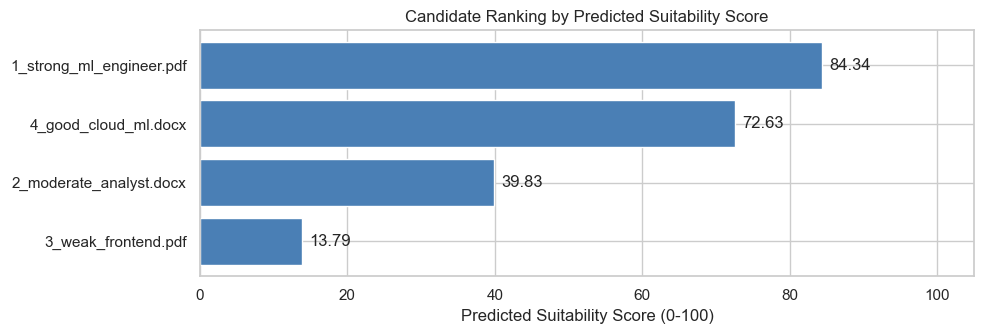


=== Detailed Candidate-Wise Analysis ===

Rank #1 | Candidate: 1_strong_ml_engineer.pdf | Score: 84.34/100 | Category (Logistic Regression): Excellent
  Matched Required Skills (6/6 - 100.0%): aws, docker, machine learning, python, scikit-learn, sql
  Missing Required Skills (0): None
  Matched Preferred Skills (66.7%): kubernetes, natural language processing
  Experience: 5 yrs (Required: 3+ yrs) | Education: Master's
  Projects: 2 total (2 JD-relevant) | Certifications: 1 total (1 JD-relevant)
  Explanation:
    * Strong match in required skills (100.0% matched).
    * Matches 2 preferred skill(s) (66.7%).
    * Meets the experience requirement (5 yrs vs 3+ yrs required).
    * Education requirement is satisfied (Master's).
    * Resume has strong TF-IDF text similarity to the JD (0.31).

Rank #2 | Candidate: 4_good_cloud_ml.docx | Score: 72.63/100 | Category (Logistic Regression): Good
  Matched Required Skills (4/6 - 66.7%): aws, docker, machine learning, python
  Missing Required

In [21]:
import tempfile

custom_jd_test = (
    "We are hiring a Senior Machine Learning Engineer. "
    "Required skills: Python, Machine Learning, AWS, Docker, SQL, Scikit-learn. "
    "Preferred: Kubernetes, PyTorch, NLP. "
    "Minimum 3+ years of experience and at least a Bachelor's degree."
)

def make_sample_pdf(path, text):
    old_fonttype = plt.rcParams.get("pdf.fonttype", 3)
    plt.rcParams["pdf.fonttype"] = 42
    fig = plt.figure(figsize=(8.5, 11))
    fig.text(0.08, 0.92, text, va="top", fontsize=10, fontfamily="DejaVu Sans")
    fig.savefig(path)
    plt.close(fig)
    plt.rcParams["pdf.fonttype"] = old_fonttype

def make_sample_docx(path, lines):
    doc = Document()
    for line in lines:
        doc.add_paragraph(line)
    doc.save(path)

with tempfile.TemporaryDirectory() as tmp_dir:
    # Build realistic test resumes with different match strengths
    pdf_strong = os.path.join(tmp_dir, "1_strong_ml_engineer.pdf")
    make_sample_pdf(
        pdf_strong,
        "Aarav Mehta\nMachine Learning Engineer\n"
        "SUMMARY\nExperienced Machine Learning Engineer with 5 years of experience.\n"
        "SKILLS\nPython, ML, Amazon Web Services, Docker, SQL, sklearn, K8s, NLP\n"
        "EXPERIENCE\nSenior ML Engineer (5 years)\n"
        "EDUCATION\nMaster of Technology in Computer Science\n"
        "PROJECTS\n- Churn Predictor built using Python and sklearn\n"
        "- Model API built using Docker and AWS\n"
        "CERTIFICATIONS\n- AWS Certified Machine Learning"
    )

    docx_moderate = os.path.join(tmp_dir, "2_moderate_analyst.docx")
    make_sample_docx(docx_moderate, [
        "Priya Sharma",
        "Data Analyst",
        "SUMMARY",
        "Data Analyst with 3 years of experience in SQL and Python.",
        "SKILLS",
        "Python, SQL, Tableau, Excel",
        "EXPERIENCE",
        "Data Analyst (3 years)",
        "EDUCATION",
        "Bachelor of Engineering",
        "PROJECTS",
        "- Sales Dashboard built using SQL",
    ])

    pdf_weak = os.path.join(tmp_dir, "3_weak_frontend.pdf")
    make_sample_pdf(
        pdf_weak,
        "Rohan Das\nFrontend Developer\n"
        "SUMMARY\nJunior Frontend Developer with 1 year of experience.\n"
        "SKILLS\nHTML, CSS, JS, React\n"
        "EXPERIENCE\nFrontend Developer (1 year)\n"
        "EDUCATION\nDiploma in Web Design"
    )

    docx_good = os.path.join(tmp_dir, "4_good_cloud_ml.docx")
    make_sample_docx(docx_good, [
        "Neha Kapoor",
        "Machine Learning Engineer",
        "SUMMARY",
        "ML Developer with 4 years of experience.",
        "SKILLS",
        "Python, Machine Learning, AWS, Docker, PyTorch",
        "EXPERIENCE",
        "ML Engineer (4 years)",
        "EDUCATION",
        "Bachelor of Technology",
        "PROJECTS",
        "- NLP Classifier built using PyTorch",
        "- Pipeline deployment using Docker",
        "CERTIFICATIONS",
        "- AWS Certified Solutions Architect",
    ])

    # Edge-case invalid files
    txt_unsupported = os.path.join(tmp_dir, "5_invalid_notes.txt")
    with open(txt_unsupported, "w", encoding="utf-8") as f:
        f.write("Python, AWS, Docker, 5 years of experience")

    pdf_blank = os.path.join(tmp_dir, "6_scanned_empty.pdf")
    from pypdf import PdfWriter
    writer = PdfWriter()
    writer.add_blank_page(200, 200)
    with open(pdf_blank, "wb") as f:
        writer.write(f)

    pdf_short = os.path.join(tmp_dir, "7_too_short.pdf")
    make_sample_pdf(pdf_short, "John Doe")

    pdf_corrupt = os.path.join(tmp_dir, "8_corrupted.pdf")
    with open(pdf_corrupt, "wb") as f:
        f.write(b"%PDF-1.4\nnot_a_valid_pdf_body")

    print("========== TEST 1: SINGLE PDF RESUME ==========")
    t1_df, t1_fail = screen_resumes(custom_jd_test, [pdf_strong], show_plots=False)
    assert t1_df is not None and len(t1_df) == 1
    assert 0.0 <= t1_df.loc[0, "Predicted Score"] <= 100.0
    assert t1_df.loc[0, "req_skill_match_pct"] == 100.0, "Strong PDF should match all 6 required skills"

    print("\n========== TEST 2: SINGLE DOCX RESUME ==========")
    t2_df, t2_fail = screen_resumes(custom_jd_test, [docx_moderate], show_plots=False)
    assert t2_df is not None and len(t2_df) == 1
    assert 0.0 <= t2_df.loc[0, "Predicted Score"] <= 100.0

    print("\n========== TEST 3: EMPTY & TOO-SHORT JOB DESCRIPTIONS ==========")
    e1_df, _ = screen_resumes("", [pdf_strong], show_plots=False)
    e2_df, _ = screen_resumes("Python job", [pdf_strong], show_plots=False)
    assert e1_df is None and e2_df is None

    print("\n========== TEST 4: NO RESUMES PROVIDED ==========")
    n_df, _ = screen_resumes(custom_jd_test, [], show_plots=False)
    assert n_df is None

    print("\n========== TEST 5: MIXED BATCH (4 VALID + UNSUPPORTED + SCANNED + TOO SHORT + CORRUPTED) ==========")
    batch_files = [
        pdf_strong, docx_moderate, pdf_weak, docx_good,
        txt_unsupported, pdf_blank, pdf_short, pdf_corrupt
    ]
    batch_df, batch_fail = screen_resumes(custom_jd_test, batch_files, show_plots=True)

    assert batch_df is not None and len(batch_df) == 4, "All 4 valid resumes should succeed"
    assert len(batch_fail) == 4, "All 4 invalid/unreadable files should be reported gracefully"
    assert batch_df["Predicted Score"].between(0, 100).all(), "Scores must stay within 0-100"
    assert batch_df["Predicted Score"].is_monotonic_decreasing, "Ranking must be descending"
    assert list(batch_df["Candidate"]) == [
        "1_strong_ml_engineer.pdf",
        "4_good_cloud_ml.docx",
        "2_moderate_analyst.docx",
        "3_weak_frontend.pdf",
    ], f"Unexpected ranking order: {list(batch_df['Candidate'])}"
    assert set(batch_df["Predicted Category"]).issubset(set(cls_bundle["category_labels"]))
    print("\nALL PHASE 3 ASSERTIONS PASSED!")

## Phase 4 & Conclusion
The trained models (`resume_screening_model.pkl` and `resume_classification_model.pkl`) and Phase 3 pipeline are integrated into the **FitScore AI** Flask web application (`app.py`, `screening_engine.py`, `templates/`, `static/`).